# SENTRY-10 · Notebook B — live acoustic safety monitor demo

An acoustic safety monitor for a (fictional) mixed-use industrial site, "Tuas Bay Works, Block 7".
An Audio Spectrogram Transformer (AST) fine-tuned on an 11-class subset of ESC-50 classifies each
5-second window; a hand-written **context layer** (zone, time of night, 5-minute correlation) turns the
label into a severity; an optional **Groq LLM** writes the supervisor alert, and **gTTS** speaks it on the
public address at HIGH and CRITICAL only. The Gradio app plays a scripted 8-beat night shift (NEXT /
back / replay / restart), listens to a **streaming microphone** with its own live spectrogram, and
accepts **file uploads** as a fallback.

**▶ Demo: Runtime → Run all — the Gradio link appears at the bottom in ~3–5 min.**
Runtime: **T4 GPU** (Runtime → Change runtime type). It also runs on CPU, more slowly.
Optional: add a Colab secret `GROQ_API_KEY` for live LLM alerts (MODE "LIVE"); without it the notebook
runs in MODE "SAFE" with the alert text cached by Notebook A.

Open the public Gradio share URL in a **new browser tab** (the microphone does not work inside the Colab
output frame). Press **🔊 test the PA** once, then **▶ NEXT** through the night.

*4-person team project (Team 10), Speech Processing and Multimodal AI, Week 8. Notebook A
(`A_train_and_evaluate.ipynb`) trains and evaluates the model and publishes it to the Hugging Face Hub.*

### The one rule for the public address

```
severity HIGH or CRITICAL  ->  the public address speaks
anything else              ->  logged, not announced
```

The night therefore ends quietly: the resolving 01:22 siren is a *response* class (help arriving), scores
MEDIUM, and is logged, not announced.


In [ ]:
# ── Demo settings ──────────────────────────────────────────────
# This notebook is the interview demo: it downloads the trained model and the demo
# artifacts from the Hugging Face Hub and launches the Gradio app (last cell).
# Training lives in Notebook A (A_train_and_evaluate.ipynb), which also pushes to HF_REPO.
HF_USER = "tantg101"          # your Hugging Face username
HF_REPO = f"{HF_USER}/sentry10-ast-esc50"



---
## 1 · Config

In [ ]:

# ══════════════════════════════════════════════════════════════════════════════
#  MODE is picked automatically:
#    "LIVE" if a Colab secret GROQ_API_KEY exists  -> the LLM writes each alert live
#    "SAFE" otherwise                              -> real model, alert text cached by Notebook A
#    ("REPLAY" = no model, cached predictions only; set MODE_OVERRIDE to force a mode)
MODE_OVERRIDE = None   # None | "LIVE" | "SAFE" | "REPLAY"
# ══════════════════════════════════════════════════════════════════════════════

PACE          = 1.0     # multiply every scripted pause. 0.6 = faster run-through
ADVANCE       = "manual"  # kept for compatibility; the NEXT button drives the beats
SHOW_CUES     = True    # print the presenter's cue line under the dashboard
USE_DRIVE     = False   # False = download model + demo artifacts from the Hugging Face Hub
                        # True  = read Notebook A's output folder from your own Google Drive

import time, json, os, sys
T0 = time.time()


def _groq_key():
    try:
        from google.colab import userdata
        return userdata.get("GROQ_API_KEY")
    except Exception:
        return os.environ.get("GROQ_API_KEY")


MODE = MODE_OVERRIDE or ("LIVE" if _groq_key() else "SAFE")

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT      = "/content/drive/MyDrive/SENTRY10"     # Notebook A's ROOT with USE_DRIVE=True
    ARTIFACTS = f"{ROOT}/artifacts"
    MODEL_DIR = f"{ARTIFACTS}/model"
else:
    try:
        from huggingface_hub import snapshot_download
    except ImportError:
        !pip install -q huggingface_hub
        from huggingface_hub import snapshot_download
    ROOT = "/content/SENTRY10" if os.path.isdir("/content") else os.path.abspath("SENTRY10")
    print(f"downloading {HF_REPO} from the Hugging Face Hub (~350 MB, first run only) ...")
    snapshot_download(repo_id=HF_REPO, local_dir=ROOT)
    ARTIFACTS = f"{ROOT}/artifacts"   # demo_cache.json, demo_audio/ev_*.wav, demo_audio/pa/*.mp3
    MODEL_DIR = ROOT                  # model.safetensors, config.json, preprocessor_config.json

assert os.path.exists(f"{ARTIFACTS}/demo_cache.json"), (
    f"No artifacts at {ARTIFACTS}. Check HF_REPO, or run Notebook A to build and push them.")
print("MODE =", MODE, "| artifacts found | ready in %.1f s" % (time.time() - T0))
if MODE == "SAFE":
    print("(no GROQ_API_KEY secret: alert text comes from Notebook A's cache; "
          "classification and severity are still computed live)")


In [ ]:

# ── Dependencies. Checked one by one, because gating them all behind gradio's
#    version is what silently disabled the LLM and the voice in v13 and earlier. ──
import importlib

_GR_MIN = (4, 44)
NEEDS = [
    # module        pip spec        what stops working without it
    ("transformers", "transformers", "the classifier"),
    ("librosa",      "librosa",      "loading audio files"),
    ("groq",         "groq",         "the LLM that writes the alert text"),
    ("gtts",         "gtts",         "the voice that speaks the announcement"),
    ("scipy",        "scipy",        "resampling browser microphone audio to 16 kHz"),
    ("soundfile",    "soundfile",    "measuring how long an announcement runs"),
]
if MODE == "REPLAY":
    NEEDS = [n for n in NEEDS if n[0] not in ("transformers", "librosa")]


def _have_mod(mod):
    try:
        importlib.import_module(mod)
        return True
    except Exception:
        return False


_missing = [spec for mod, spec, _why in NEEDS if not _have_mod(mod)]
if _missing:
    print("installing:", " ".join(_missing))
    !pip install -q -U {" ".join(_missing)} 2>&1 | tail -2
    importlib.invalidate_caches()
else:
    print("all non-gradio dependencies already present")


# gradio keeps its own guard. Its version is read from the installed package metadata
# WITHOUT importing it, so an upgrade here never leaves an old gradio in memory and
# no runtime restart is needed: gradio is first imported by the app cell further down.
def _gr_version():
    try:
        import re
        from importlib.metadata import version
        m = re.match(r"(\d+)\.(\d+)", version("gradio"))
        return (int(m.group(1)), int(m.group(2))) if m else None
    except Exception:
        return None


_have = _gr_version()
if _have is None or _have < _GR_MIN:
    !pip install -q -U "gradio>=4.44" 2>&1 | tail -1
    importlib.invalidate_caches()
_have = _gr_version()

# ── Verify. Never assume an install worked; this table is the whole point of the cell.
print("\n" + "=" * 68)
_bad = []
for _mod, _spec, _why in NEEDS:
    if _have_mod(_mod):
        _v = getattr(importlib.import_module(_mod), "__version__", "")
        print(f"  ok  {_mod:<13} {str(_v):<12} {_why}")
    else:
        _bad.append((_mod, _why))
        print(f"  XX  {_mod:<13} {'MISSING':<12} {_why}")
print(f"  {'ok ' if _have and _have >= _GR_MIN else 'XX '} "
      f"{'gradio':<13} {'.'.join(map(str, _have)) if _have else 'MISSING':<12} "
      f"serves the demo app")
print("=" * 68)

if _bad:
    print("\n*** SOME DEPENDENCIES ARE MISSING. Consequences: ***")
    for _mod, _why in _bad:
        print(f"      no {_mod}  ->  {_why} WILL NOT WORK")
    print("    Re-run this cell. If it still fails, the runtime has no network.")
elif _have is None or _have < _GR_MIN:
    print("\ngradio could not be installed or upgraded - re-run this cell.")
    print("If it still fails, the runtime has no network.")
else:
    print("\nall dependencies ready — the LLM and the live voice can both run")


---
## 2 · Load everything

One cell. Loads the cache always, and the model only if the mode needs it.

In [ ]:

import json, numpy as np, base64, io, textwrap
from IPython.display import HTML, Audio, display, clear_output

CACHE = json.load(open(f"{ARTIFACTS}/demo_cache.json"))
EVENTS   = CACHE["events"]
ZONES    = CACHE["zones"]
METRICS  = CACHE["metrics"]
CLASSES  = CACHE["classes"]
TAU      = CACHE["tau"]
AUDIO    = f"{ARTIFACTS}/demo_audio"
# scratch space for incident cards, the log csv and live-rendered PA audio
WORKDIR  = globals().get("WORKDIR") or ("/content" if os.path.isdir("/content") else ".")
# Notebook A recorded where it found the course sample library; the challenge-round
# backup reads from there rather than guessing a path relative to ROOT.
SAMPLES  = CACHE.get("audiosamples_dir") or f"{ROOT}/AudioSamples"

LADDER = ["INFO", "LOW", "MEDIUM", "HIGH", "CRITICAL"]
SEVCOL = {"INFO": "#4c7fb0", "LOW": "#4b9e73", "MEDIUM": "#d99a2b",
          "HIGH": "#d9642b", "CRITICAL": "#c0392b"}
ZONE_ORDER = ["Z1", "Z2", "Z3", "Z4"]

def M(key, default=float("nan")):
    # Notebook A writes None (not a missing key) for the cross-source figures when the
    # optional AudioSamples evaluation was skipped, so `.get(k, default)` is not enough.
    v = METRICS.get(key)
    return default if v is None else v

model = fe = None
if MODE in ("LIVE", "SAFE"):
    import torch, librosa
    from transformers import ASTForAudioClassification, ASTFeatureExtractor
    t = time.time()
    # MODEL_DIR is set in the config cell: the Hugging Face snapshot root by default
    model = ASTForAudioClassification.from_pretrained(MODEL_DIR)
    fe    = ASTFeatureExtractor.from_pretrained(MODEL_DIR)
    model.eval()
    if torch.cuda.is_available():
        model = model.to("cuda").half()
    print(f"model loaded in {time.time()-t:.1f} s on "
          f"{'GPU' if torch.cuda.is_available() else 'CPU'}")

if METRICS.get("have_cross_source"):
    xs_line = f"{M('cross_source_recall_exact'):.3f} recall on the course sample library"
else:
    xs_line = "not run (no AudioSamples folder) - see the unseen-negative figure above"

print("\n".join([
    "",
    f"  built         {CACHE['built_at']}",
    f"  classes       {len(CLASSES)}   confidence gate tau = {TAU}",
    f"  in-domain     {METRICS['in_domain_accuracy']:.3f} accuracy on ESC-50 fold 5",
    f"  linear probe  {M('linear_probe_accuracy'):.3f} accuracy (frozen backbone baseline)",
    f"  false alarms  {M('unseen_negative_false_alarm_rate'):.3f} on "
    f"{METRICS.get('n_unseen_negatives', 0)} unseen impulsive clips",
    f"  degraded mic  {M('channel_shift_recall'):.3f} recall through a simulated bad channel",
    f"  cross-source  {xs_line}",
    f"  demo events   {len(EVENTS)}",
    "",
]))

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

model loaded in 13.1 s on GPU

  built         2026-08-04T08:29:36
  classes       11   confidence gate tau = 0.45
  in-domain     0.981 accuracy on ESC-50 fold 5
  linear probe  0.994 accuracy (frozen backbone baseline)
  false alarms  0.308 on 240 unseen impulsive clips
  degraded mic  0.562 recall through a simulated bad channel
  cross-source  0.600 recall on the course sample library
  demo events   8



In [ ]:

# ---------------------------------------------------------------- classifier
import numpy as np

def classify(path_or_array, sr=16000, win_s=5.0, hop_s=2.5, max_windows=12):
    # 5 s windows with a 2.5 s hop, so an event that straddles a window boundary is not
    # lost. Returns (gated label, confidence, probability vector) for the single most
    # confident window -- the same rule the cross-source evaluation in Notebook A uses.
    if MODE == "REPLAY":
        raise RuntimeError("classify() is not available in REPLAY mode; use replay_clip()")
    import torch, librosa
    if isinstance(path_or_array, str):
        y, _ = librosa.load(path_or_array, sr=sr, mono=True)
    else:
        y = np.asarray(path_or_array, dtype=np.float32)
    n, hop = int(win_s * sr), int(hop_s * sr)
    if len(y) < n:
        y = np.pad(y, (0, n - len(y)))
    wins = [y[i:i + n] for i in range(0, max(1, len(y) - n + 1), hop)][:max_windows]
    with torch.no_grad():
        f_ = fe(wins, sampling_rate=sr, return_tensors="pt")["input_values"]
        f_ = f_.to(model.device).to(model.dtype)
        pr = torch.softmax(model(input_values=f_).logits.float(), dim=1).cpu().numpy()
    best = pr.max(1).argmax()                       # the window it is most sure about
    p = pr[best]
    lab = CLASSES[int(p.argmax())] if p.max() >= TAU else "background_other"
    return lab, float(p.max()), p

# ─────────────────────────────────────────────────────────────────────────────
#  THE CONTEXT LAYER
#  This is the part that turns a sound classifier into a safety system, and it is
#  the part worth talking about in the demo. Four rules, in this order:
#
#    1. ZONE      the same class means different things in different rooms
#    2. HOURS     out-of-hours activity is more suspicious than the same thing at noon
#    3. EXCEPTIONS  two named carve-outs that pure arithmetic gets wrong
#    4. CORRELATION  events inside a 5-minute window are one situation, not several
#
#  Every rule is hand-written and auditable. That is deliberate: an escalation
#  policy is a safety document. A safety officer has to be able to read it,
#  disagree with a line, and change that line. A learned policy cannot offer that.
# ─────────────────────────────────────────────────────────────────────────────
LADDER = ["INFO", "LOW", "MEDIUM", "HIGH", "CRITICAL"]

BASE_SEV = {"glass_breaking": "HIGH",  "siren": "MEDIUM",   "clock_alarm": "HIGH",
            "crying_baby":    "MEDIUM","chainsaw": "MEDIUM","hand_saw": "LOW",
            "car_horn":       "LOW",   "engine": "INFO",    "vacuum_cleaner": "INFO",
            "footsteps":      "INFO",  "background_other": "INFO"}

# steps up (+) or down (-) the ladder, per zone
ZONE_MOD = {
 "Z1": {"glass_breaking": -1, "crying_baby": +2, "chainsaw": 0,  "hand_saw": 0,
        "engine": -1, "vacuum_cleaner": -1, "footsteps": -1},
 "Z2": {"glass_breaking": +2, "crying_baby": +2, "chainsaw": +2, "hand_saw": +2,
        "engine": +2, "vacuum_cleaner": +1, "footsteps": +2, "clock_alarm": +1},
 "Z3": {"glass_breaking": +1, "crying_baby": -2, "chainsaw": +2, "hand_saw": +2,
        "engine": +1, "footsteps": -1, "clock_alarm": +1},
 "Z4": {"glass_breaking": +1, "crying_baby": +2, "car_horn": -1, "engine": -1,
        "footsteps": 0},
}

OOH_CLASSES      = {"glass_breaking", "chainsaw", "hand_saw", "footsteps", "engine"}
RESPONSE_CLASSES = {"siren"}       # emergency response ARRIVING is not a new threat
DISTRESS_CLASSES = {"crying_baby"} # human distress: suppression is revoked mid-incident
WINDOW_MIN       = 5


def _mins(clock):
    h, m = int(clock[:2]), int(clock[3:])
    return (h if h >= 12 else h + 24) * 60 + m      # night shift wraps past midnight


def in_window(a, b):
    return abs(_mins(a) - _mins(b)) <= WINDOW_MIN


def severity(cls, zone, clock, recent):
    # recent = list of dicts {clock, zone, label, severity} already inside the window
    step, why = LADDER.index(BASE_SEV.get(cls, "INFO")), []
    incident_open = any(r["severity"] == "CRITICAL" for r in recent)

    # --- rule 1 + exception A: zone, unless suppression has been revoked ----------
    zmod = ZONE_MOD.get(zone, {}).get(cls, 0)
    if zmod < 0 and incident_open and cls in DISTRESS_CLASSES:
        why.append(f"zone {zone} {zmod:+d} SUPPRESSION REVOKED (incident open)")
        zmod = 0
    if zmod:
        step += zmod
        why.append(f"zone {zone} {zmod:+d}")

    # --- rule 2: out of hours ------------------------------------------------------
    hour = int(clock[:2])
    if (hour >= 21 or hour < 6) and cls in OOH_CLASSES:
        step += 1
        why.append("out of hours +1")

    # --- exception B: response classes never escalate -------------------------------
    if cls in RESPONSE_CLASSES:
        why.append("response class, exempt from escalation")
        return LADDER[max(0, min(4, step))], why

    # --- rule 4: correlation --------------------------------------------------------
    prior = [r for r in recent if LADDER.index(r["severity"]) >= LADDER.index("MEDIUM")]
    cross = (not incident_open and len(prior) >= 2
             and len({r["zone"] for r in prior} | {zone}) >= 2)
    if prior and LADDER.index(BASE_SEV.get(cls, "INFO")) >= LADDER.index("LOW"):
        step += 1
        why.append(f"correlated with {len(prior)} recent alert(s) +1")
    if cross:
        step += 1
        why.append("cross-zone cascade +1")

    # Only a cross-zone cascade may declare CRITICAL. Once an incident is already
    # open we stop ratcheting: further events are scored on their own merits.
    cap = 4 if cross else 3
    return LADDER[max(0, min(cap, step))], why

print("classifier + severity engine ready")

classifier + severity engine ready


In [ ]:

# ---------------------------------------------------------------- LLM alert writer
SYSTEM_PROMPT = (
 "You are the alert writer for SENTRY-10, an acoustic safety monitor at a mixed-use industrial site "
 "in Singapore. You receive ONLY a list of detected sound events with zone, time, confidence and a "
 "computed severity. You never receive audio and never receive speech transcripts.\n\n"
 "Write the alert a night-shift supervisor should read. Rules:\n"
 "1. Two sentences maximum. Lead with what to DO, not with what was heard.\n"
 "2. Name the zone in plain language, not the code.\n"
 "3. If several events are correlated, describe them as ONE situation, not a list.\n"
 "4. State the confidence honestly. If it is below 0.7, say the detection is uncertain.\n"
 "5. Never invent detail that is not in the event data.\n"
 "6. Plain English. No emoji, no markdown, no preamble."
)

def template_alert(cls, zone, clock, conf, sev, recent):
    z = ZONES[zone]["name"]
    if sev in ("INFO", "LOW"):
        return (f"No action required. {cls.replace('_',' ').capitalize()} detected in the {z} "
                f"at {clock}; consistent with normal operation.")
    lead = {"MEDIUM": "Check", "HIGH": "Attend", "CRITICAL": "Evacuate and attend"}[sev]
    extra = (f" This follows {len(recent)} related detection(s) in the last five minutes."
             if recent else "")
    unsure = " Detection confidence is low; verify before escalating." if conf < 0.7 else ""
    return (f"{lead} the {z} now: {cls.replace('_',' ')} detected at {clock} "
            f"(confidence {conf:.2f}).{extra}{unsure}")

_groq_client = None

# ── ALERT WRITER ─────────────────────────────────────────────────────────────
# v13. Two changes, both because of one demo: the reasoning line read "alert via
# cached" while MODE was LIVE, and nobody could tell why.
#
#   1  The reason is now ON SCREEN. write_alert() already fell back silently to the
#      cached text when Groq raised -- and reported it with a print() into a cell
#      output nobody watches mid-demo. Exactly the mistake the PA made in v6. The
#      source string now carries the exception, so the dashboard says
#      "alert via cached (groq: AuthenticationError)" and you can act on it.
#
#   2  Groq retires models on a rolling basis and answers with a decommission error.
#      One dead model name should not silently switch off the live LLM, so there
#      is a fallback list and it remembers which one worked.
GROQ_MODELS = ["llama-3.3-70b-versatile", "llama-3.1-8b-instant", "openai/gpt-oss-20b"]
GROQ_TIMEOUT = 20          # generous: the alert is written on a worker thread now
ALERT_STATUS = {"last": "not written yet", "groq_ok": None, "groq_fails": 0,
                "model": None, "last_error": ""}


def groq_alert(cls, zone, clock, conf, sev, why, recent, timeout=GROQ_TIMEOUT):
    global _groq_client
    from groq import Groq
    if _groq_client is None:
        key = None
        try:
            from google.colab import userdata
            key = userdata.get("GROQ_API_KEY")
        except Exception:
            key = os.environ.get("GROQ_API_KEY")
        if not key:
            raise RuntimeError("GROQ_API_KEY not found — add it to Colab Secrets and "
                               "switch on notebook access for this notebook")
        _groq_client = Groq(api_key=key)
    payload = {"current_event": {"time": clock, "zone": zone, "zone_name": ZONES[zone]["name"],
                                 "zone_type": ZONES[zone]["type"], "sound": cls,
                                 "confidence": round(conf, 3), "computed_severity": sev,
                                 "why_this_severity": why},
               "recent_events_last_5_min": recent}
    order = ([ALERT_STATUS["model"]] if ALERT_STATUS["model"] else []) + \
            [m for m in GROQ_MODELS if m != ALERT_STATUS["model"]]
    last = None
    for model in order:
        try:
            r = _groq_client.chat.completions.create(
                model=model, temperature=0.3, max_tokens=140, timeout=timeout,
                messages=[{"role": "system", "content": SYSTEM_PROMPT},
                          {"role": "user", "content": json.dumps(payload)}])
            ALERT_STATUS["model"] = model
            return r.choices[0].message.content.strip(), model
        except Exception as e:
            last = e
            # Only walk to the next model for a model-level rejection; a bad key or a
            # dead network will fail identically on all three and just waste 60 s.
            if not any(w in f"{type(e).__name__}: {e}".lower()
                       for w in ("decommission", "not found", "does not exist",
                                 "model_not_found", "unsupported")):
                raise
    raise last


def write_alert(cls, zone, clock, conf, sev, why, recent, cached=None):
    """LIVE tries Groq and degrades in the open. SAFE/REPLAY use Notebook A's text."""
    if MODE == "LIVE":
        try:
            txt, model = groq_alert(cls, zone, clock, conf, sev, why, recent)
            ALERT_STATUS.update(last=f"groq live ({model})", groq_ok=True, last_error="")
            return txt, f"groq live · {model}"
        except Exception as e:
            err = f"{type(e).__name__}: {e}"
            ALERT_STATUS["groq_fails"] += 1
            ALERT_STATUS["groq_ok"] = False
            ALERT_STATUS["last_error"] = err[:160]
            ALERT_STATUS["last"] = f"FELL BACK — groq failed: {err[:110]}"
            print(f"  [groq] {err}")
            short = type(e).__name__
            if cached:
                return cached, f"cached (groq failed: {short})"
            return (template_alert(cls, zone, clock, conf, sev, recent),
                    f"template (groq failed: {short})")
    if cached:
        ALERT_STATUS["last"] = f"cached from Notebook A (MODE={MODE})"
        return cached, "cached"
    ALERT_STATUS["last"] = f"template (MODE={MODE})"
    return template_alert(cls, zone, clock, conf, sev, recent), "template"


print("alert writer ready ·", " -> ".join(GROQ_MODELS))


### The control-room dashboard

Rendered as HTML and updated in place, so the audience sees one panel changing rather than a wall of
scrolling output. The zone tiles are laid out to match the site plan in the case study: machine hall
across the top left, the two small ground-floor rooms below it, the perimeter down the right.

In [ ]:

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

def spec_b64(y, sr=16000, w=3.4, h=1.15):
    # A small spectrogram thumbnail, base64-encoded so it can sit inside the dashboard HTML.
    fig, ax = plt.subplots(figsize=(w, h))
    ax.specgram(np.asarray(y, dtype=float), Fs=sr, NFFT=512, noverlap=384,
                cmap="magma", vmin=-110, vmax=-20)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110, bbox_inches="tight", pad_inches=0)
    plt.close(fig)
    return base64.b64encode(buf.getvalue()).decode()

def bars_html(probs, top=4):
    idx = np.argsort(probs)[::-1][:top]
    rows = ""
    for i in idx:
        pct = float(probs[i]) * 100
        col = "#2c5f8a" if i == idx[0] else "#9aa7b5"
        rows += (f"<div style='display:flex;align-items:center;gap:6px;margin:2px 0'>"
                 f"<div style='width:112px;font-size:10px;text-align:right;color:#4a5563'>"
                 f"{CLASSES[i].replace('_',' ')}</div>"
                 f"<div style='flex:1;background:#e6eaef;height:9px;border-radius:5px'>"
                 f"<div style='width:{pct:.0f}%;background:{col};height:9px;border-radius:5px'></div>"
                 f"</div><div style='width:34px;font-size:10px;color:#4a5563'>{pct:.0f}%</div></div>")
    return rows

def dashboard(clock="--:--", active=None, state=None, alert="", feed=None,
              spec=None, probs=None, status="MONITORING", cue=""):
    state = state or {z: ("IDLE", "") for z in ZONE_ORDER}
    feed = feed or []
    sc = {"MONITORING": "#4b9e73", "INCIDENT OPEN": "#c0392b", "RESOLVING": "#d99a2b",
          "STANDBY": "#6b7787"}.get(status, "#6b7787")

    def tile(z, tall=False):
        sev, lab = state.get(z, ("IDLE", ""))
        on = z == active
        col = SEVCOL.get(sev, "#9aa7b5")
        bg = f"linear-gradient(180deg,{col}22,{col}0d)" if sev != "IDLE" else "#f4f6f9"
        ring = f"0 0 0 3px {col}55" if on else "none"
        return (f"<div style='border:2px solid {col if sev!='IDLE' else '#d5dbe3'};"
                f"border-radius:9px;background:{bg};box-shadow:{ring};padding:9px 11px;"
                f"min-height:{'188' if tall else '80'}px;transition:all .25s'>"
                f"<div style='font:700 12px system-ui;color:{col if sev!='IDLE' else '#6b7787'}'>"
                f"{z} &nbsp;{ZONES[z]['name']}</div>"
                f"<div style='font:10px system-ui;color:#8b95a3;margin-top:1px'>"
                f"{ZONES[z]['type']}</div>"
                f"<div style='margin-top:7px;font:700 13px system-ui;color:#1c2430'>"
                f"{lab.replace('_',' ') if lab else '&mdash;'}</div>"
                f"<div style='font:700 10px system-ui;color:{col};letter-spacing:.6px'>"
                f"{sev if sev!='IDLE' else 'nominal'}</div></div>")

    feed_html = "".join(
        f"<div style='display:flex;gap:8px;font:11px ui-monospace,monospace;padding:3px 0;"
        f"border-bottom:1px solid #eef1f4'>"
        f"<span style='color:#8b95a3;width:42px'>{f_['clock']}</span>"
        f"<span style='color:#6b7787;width:26px'>{f_['zone']}</span>"
        f"<span style='flex:1;color:#1c2430'>{f_['label'].replace('_',' ')}</span>"
        f"<span style='color:{SEVCOL[f_['severity']]};font-weight:700'>{f_['severity']}</span></div>"
        for f_ in feed[-7:][::-1])

    spec_html = (f"<img src='data:image/png;base64,{spec}' style='width:100%;border-radius:6px'/>"
                 if spec else "<div style='height:74px;background:#f4f6f9;border-radius:6px'></div>")
    bars = bars_html(probs) if probs is not None else \
        "<div style='font:11px system-ui;color:#9aa7b5;padding:14px 0'>awaiting audio…</div>"
    alert_html = (f"<div style='font:13px/1.55 system-ui;color:#1c2430'>{alert}</div>"
                  if alert else
                  "<div style='font:12px system-ui;color:#9aa7b5'>no active alert</div>")
    cue_html = (f"<div style='margin-top:8px;font:italic 11px system-ui;color:#a9b2bd;"
                f"border-top:1px dashed #dfe4ea;padding-top:6px'>presenter cue &nbsp;·&nbsp; {cue}</div>"
                if (cue and SHOW_CUES) else "")

    return HTML(f"""
<div style="font-family:system-ui,-apple-system,sans-serif;max-width:980px;border:1px solid #d5dbe3;
            border-radius:12px;overflow:hidden;background:#fff">
  <div style="background:#1c2430;color:#fff;padding:11px 16px;display:flex;
              align-items:center;gap:14px">
    <div style="font:800 15px system-ui;letter-spacing:1.2px">SENTRY&#8209;10</div>
    <div style="font:11px system-ui;color:#9aa7b5">Tuas Bay Works, Block 7 &nbsp;·&nbsp; night shift</div>
    <div style="flex:1"></div>
    <div style="font:700 20px ui-monospace,monospace;letter-spacing:1px">{clock}</div>
    <div style="background:{sc};padding:4px 11px;border-radius:20px;font:700 10px system-ui;
                letter-spacing:1px">{status}</div>
  </div>
  <div style="display:grid;grid-template-columns:1.35fr 1fr;gap:12px;padding:13px">
    <div style="display:grid;grid-template-columns:1fr 1fr;gap:9px">
      <div style="grid-column:1/3">{tile('Z1')}</div>
      {tile('Z2')}{tile('Z3')}
      <div style="grid-column:1/3">{tile('Z4')}</div>
    </div>
    <div>
      <div style="font:700 10px system-ui;color:#8b95a3;letter-spacing:1px;margin-bottom:4px">
        LIVE SPECTROGRAM</div>
      {spec_html}
      <div style="font:700 10px system-ui;color:#8b95a3;letter-spacing:1px;margin:9px 0 3px">
        CLASSIFIER OUTPUT</div>
      {bars}
      <div style="font:700 10px system-ui;color:#8b95a3;letter-spacing:1px;margin:9px 0 3px">
        EVENT LOG</div>
      <div style="max-height:132px;overflow:hidden">{feed_html}</div>
    </div>
  </div>
  <div style="background:#f7f9fb;border-top:1px solid #e4e9ee;padding:11px 16px">
    <div style="font:700 10px system-ui;color:#8b95a3;letter-spacing:1px;margin-bottom:4px">
      SUPERVISOR ALERT</div>
    {alert_html}{cue_html}
  </div>
</div>""")

display(dashboard(status="STANDBY", cue="this is the panel the room will watch"))


---
## 3 · Self-test — run this before the class arrives

Twenty seconds. Exercises every part of the chain on one clip so that nothing is discovered for the
first time in front of an audience. If a line says FAIL, drop `MODE` down a level and run it again.

In [ ]:

ok = True
def t(label, fn):
    global ok
    try:
        r = fn()
        print(f"  PASS  {label}" + (f"   {r}" if r else ""))
        return True
    except Exception as e:
        ok = False
        print(f"  FAIL  {label}   {type(e).__name__}: {e}")
        return False

print("SELF-TEST  ({} mode)\n".format(MODE))
t("artifacts + cache readable", lambda: f"{len(EVENTS)} events, tau={TAU}")
t("event wavs present",
  lambda: f"{sum(os.path.exists(f'{AUDIO}/' + e['file']) for e in EVENTS)}/{len(EVENTS)} found")
t("PA mp3s present",
  lambda: f"{len(os.listdir(f'{AUDIO}/pa')) if os.path.exists(f'{AUDIO}/pa') else 0} rendered")

if MODE != "REPLAY":
    def _cls():
        import librosa
        y, _ = librosa.load(f"{AUDIO}/{EVENTS[4]['file']}", sr=16000)
        lab, conf, pr = classify(y)
        assert lab == EVENTS[4]["truth"], f"expected {EVENTS[4]['truth']}, got {lab}"
        return f"{lab} @ {conf:.2f}"
    t("model inference on the glass-break clip", _cls)

def _sev():
    s, w = severity("crying_baby", "Z3", "01:17",
                    [{"zone":"Z1","severity":"HIGH"},{"zone":"Z2","severity":"CRITICAL"}])
    assert s in ("HIGH", "CRITICAL"), s
    return f"{s}  ({'; '.join(w)})"
t("severity engine escalates the punchline", _sev)

if MODE == "LIVE":
    t("Groq reachable",
      lambda: groq_alert("glass_breaking","Z1","01:14",0.91,"HIGH",["zone Z1 -1"],[])[0][:58] + "…")

# gTTS needs the network. That only matters in LIVE mode: SAFE and REPLAY play the mp3s
# Notebook A already rendered. So this is a hard check in LIVE and a soft one otherwise --
# a red FAIL here when the pre-rendered audio is sitting on disk is a false alarm, and a
# false alarm in the pre-flight check is exactly what makes people ignore pre-flight checks.
_pa_ready = (os.path.isdir(f"{AUDIO}/pa")
             and len([x for x in os.listdir(f"{AUDIO}/pa") if x.endswith(".mp3")]) >= 4)

def _tts():
    from gtts import gTTS
    p_ = os.path.join(WORKDIR, "_selftest.mp3")
    gTTS("System check complete.", lang="en", tld="com.au").save(p_)
    return f"{os.path.getsize(p_)} bytes"

if MODE == "LIVE" or not _pa_ready:
    t("gTTS renders a PA line (required in this mode)", _tts)
else:
    try:
        _tts(); print("  PASS  gTTS renders a PA line")
    except Exception as e:
        print(f"  WARN  gTTS unreachable ({type(e).__name__}) - not needed, "
              f"pre-rendered PA audio is present")

print("\n" + ("ALL GREEN — you are clear to present."
              if ok else "SOMETHING FAILED — drop MODE one level and re-run cells 1-3."))


---
## 4 · Audio primer  ·  **click play once**

Browsers block autoplay until the user has interacted with the page. Click play on the tone below once
at the start of the session and every later clip will fire on its own. Skipping this is the single most
common way a rehearsed audio demo goes silent.

In [ ]:

import numpy as np
from IPython.display import Audio, display
sr = 16000
tt = np.arange(int(sr * 0.9)) / sr
chime = 0.25 * (np.sin(2*np.pi*660*tt) * np.exp(-tt*2.2) +
                np.sin(2*np.pi*990*tt) * np.exp(-tt*3.0))
print("Click play. You should hear a short two-tone chime. Set laptop volume to about 80%.")
display(Audio(chime, rate=sr))

Click play. You should hear a short two-tone chime. Set laptop volume to about 80%.



---
### 4c · PA pre-flight &nbsp;—&nbsp; run this before the class walks in

The v6 fault was invisible until a HIGH alert landed in front of an audience. This cell
makes it visible in four seconds. **Either verdict is fine to present on** — you only
need to know which one you are on.

In [ ]:

# ── Will the public address actually speak?  Answer this BEFORE the demo. ──────
# Checks both sources independently, because v7 uses the pre-rendered mp3 as a real
# fallback rather than as a thing it forgets the moment gTTS misbehaves.
import os, threading, time

_need = [e for e in EVENTS if e.get("pa_file")]
_have = [e for e in _need if os.path.isfile(os.path.join(AUDIO, "pa", e["pa_file"]))]
print(f"pre-rendered PA mp3s : {len(_have)}/{len(_need)} present"
      f"   ({os.path.join(AUDIO, 'pa')})")
for e in _need:
    p = os.path.join(AUDIO, "pa", e["pa_file"])
    ok = os.path.isfile(p)
    kb = f"{os.path.getsize(p)/1024:6.0f} kB" if ok else "MISSING"
    print(f"   {'ok ' if ok else 'XX '} {e['clock']} {e['zone']} {e['beat']:<12} {kb}")

# gTTS, with the same 8 s limit the demo uses.
_res = {}


def _probe():
    try:
        from gtts import gTTS
        gTTS("Public address test.", lang="en", tld="com.au").save(
            os.path.join(WORKDIR, "_pa_probe.mp3"))
        _res["ok"] = True
    except Exception as exc:
        _res["err"] = exc


_t0 = time.time()
_th = threading.Thread(target=_probe, daemon=True)
_th.start()
_th.join(8.0)
if _th.is_alive():
    _live = False
    _why = "no answer in 8 s"
elif _res.get("ok"):
    _live, _why = True, f"{time.time() - _t0:.1f} s"
else:
    _live = False
    _why = f"{type(_res.get('err')).__name__}"

print(f"\nlive gTTS            : {'reachable' if _live else 'NOT reachable'}  ({_why})")

print("\n" + "=" * 68)
if _live and len(_have) == len(_need):
    print("VERDICT  PA will speak with a live voice, and the mp3s are there if the")
    print("         network drops mid-demo. Nothing to do.")
elif len(_have) == len(_need):
    print("VERDICT  PA will speak from the pre-rendered mp3s. THIS IS FINE -- the room")
    print("         cannot tell, and it is what the recorded fallback used anyway.")
    print("         The cue line will read 'PA: pre-rendered mp3'. Expect that.")
elif _live:
    print("VERDICT  PA will speak, but live only, with no safety net. If you can, get")
    print("         artifacts/demo_audio/pa/ onto this machine before you present.")
else:
    print("VERDICT  *** THE PA WILL BE SILENT. ***  No mp3s and no gTTS.")
    print("         Re-run the config cell (it re-downloads artifacts/), or re-run Notebook A")
    print("         Step 8. Do not discover this during the demo -- v6 did.")
print("=" * 68)


---
### 4d · Microphone pre-flight &nbsp;—&nbsp; also before the class walks in

The microphone cannot be tested from inside the Colab output frame, so this cell checks
everything *except* the browser permission, and tells you what to do about the rest.

In [ ]:

# ── Can the live microphone path work at all on this machine? ─────────────────
import importlib, os

print("MODE =", MODE)
if MODE == "REPLAY":
    print("  !! REPLAY has no model loaded, so live detection is DISABLED.")
    print("     The scripted NEXT button still works. Set MODE to SAFE or LIVE for the mic.")
else:
    print("  ok  a model is loaded, so live windows can be classified")

for _m, _why in [("scipy", "resamples 48 kHz browser audio down to 16 kHz"),
                 ("soundfile", "reads PA length, to set the deaf window"),
                 ("gradio", "serves the streaming microphone")]:
    try:
        _v = getattr(importlib.import_module(_m), "__version__", "?")
        print(f"  ok  {_m:<11} {_v:<10} {_why}")
    except Exception as _e:
        print(f"  XX  {_m:<11} MISSING    {_why}  ({type(_e).__name__})")

# The resampler fallback is nearest-neighbour and audibly worse, so it is worth knowing
# in advance which one is in play.
try:
    from scipy.signal import resample_poly  # noqa: F401
    print("\n  resampler   : scipy.resample_poly (good)")
except Exception:
    print("\n  resampler   : nearest-neighbour fallback — install scipy for better audio")

print("""
WHAT YOU STILL HAVE TO CHECK BY HAND
  1  Open the PUBLIC URL in its own browser tab. Not the inline frame -- a browser
     will not give the microphone to a page embedded in Colab output.
  2  Press record on 'open microphone'. Grant permission. Do this in REHEARSAL: the
     Chrome prompt can open BEHIND the tab and it is a bad thing to discover on stage.
  3  Watch the panel count windows. If the numbers move, the mic is working.
  4  Play a chainsaw or an alarm off a phone. It should raise an event and speak.

IF THE ROOM'S LAPTOP BLOCKS THE MICROPHONE
  Use the file drop under the mic. It runs the identical path -- same gate, same
  severity rules, same PA -- so the demo survives with nothing rewritten.
""")


---
### 4e · Live-pipeline check &nbsp;—&nbsp; what you are allowed to claim

The alert writer and the voice **both degrade silently on purpose**, so the demo keeps
running when a network call fails. The cost of that is you cannot tell a live run from a
cached one by looking. This cell calls both services for real and tells you which
sentence you are entitled to say.

In [ ]:

# ── 4e · IS THE LIVE PIPELINE ACTUALLY LIVE?  Run this before you claim it is. ──
# The demo says the alert is "written by an LLM and spoken by text-to-speech, live".
# This cell is what entitles you to say that sentence. Both calls degrade silently by
# design, so without this you cannot tell a live run from a cached one.
import importlib, time as _t

# Import check FIRST. A missing package and a dead network produce completely different
# fixes, and in v13 they produced the same unhelpful message -- which is exactly how the
# real cause (groq was never installed) stayed hidden.
_gone = [m for m in ("groq", "gtts") if not importlib.util.find_spec(m)]
if _gone:
    print("*** " + ", ".join(_gone) + " IS NOT INSTALLED ***")
    print("    This is a packaging problem, not a network one. Re-run cell 3 (installs)")
    print("    and check its verification table before running this again.\n")

print("MODE =", MODE)
if MODE != "LIVE":
    print("  MODE is not LIVE -> alerts come from Notebook A's cache and the PA from")
    print("  pre-rendered mp3s. That is a fine way to present; just do not call it live.")

# 1 · Groq
_ok_groq = False
if MODE == "LIVE":
    _t0 = _t.time()
    try:
        _txt, _model = groq_alert("glass_breaking", "Z1", "01:12", 0.97, "HIGH",
                                  ["out of hours +1"], [])
        _ok_groq = True
        print(f"  ok  Groq        {_model}  in {_t.time() - _t0:.1f}s")
        print(f"      sample: {_txt[:96]}...")
    except Exception as _e:
        print(f"  XX  Groq        FAILED after {_t.time() - _t0:.1f}s")
        print(f"      {type(_e).__name__}: {_e}")
        if isinstance(_e, ModuleNotFoundError):
            print("      -> the groq PACKAGE is missing. Re-run cell 3. Nothing to do")
            print("         with your API key or the network.")
        else:
            print("      -> most likely GROQ_API_KEY missing from Colab Secrets, or the")
            print("         secret exists but notebook access is not switched on for it.")

# 2 · gTTS, on a realistic sentence length rather than two words
_ok_tts = False
_t0 = _t.time()
try:
    from gtts import gTTS
    _long = ("Attention. Priority alert. Attend the machine hall now: glass breaking "
             "detected at 01:12 with confidence 0.97, out of scheduled hours.")
    gTTS(_long, lang="en", tld="com.au").save(os.path.join(WORKDIR, "_tts_probe.mp3"))
    _ok_tts = True
    print(f"  ok  gTTS        rendered a full alert in {_t.time() - _t0:.1f}s")
except Exception as _e:
    print(f"  XX  gTTS        FAILED after {_t.time() - _t0:.1f}s")
    print(f"      {type(_e).__name__}: {_e}")
    if isinstance(_e, ModuleNotFoundError):
        print("      -> the gtts PACKAGE is missing. Re-run cell 3.")

print("\n" + "=" * 70)
if MODE == "LIVE" and _ok_groq and _ok_tts:
    print("SAY THIS:  'the alert is written by an LLM and spoken by text-to-speech,")
    print("            live, right now.'   Both calls just succeeded.")
elif MODE == "LIVE" and _ok_tts:
    print("SAY THIS:  'the announcement is synthesised live; the alert text is our")
    print("            cached copy because Groq is not reachable from this network.'")
    print("DO NOT claim the LLM is running. The dashboard will say so anyway.")
elif MODE == "LIVE" and _ok_groq:
    print("SAY THIS:  'the alert is written live by the LLM; the voice is pre-rendered.'")
else:
    print("SAY THIS:  'alert text and announcement are both pre-generated for")
    print("            reliability; the classification and the severity are live.'")
    print("That is still true, still worth marks, and it is honest.")
print("=" * 70)


---
# 5 · THE DEMO

The cell below builds the app and the **last cell** of the notebook launches it; **open its public URL in a new tab**. Two things before you
start: press **🔊 test the PA**, and pick a **playback speed** (1.5× suits a ten-minute
slot). The speed now holds for everything that follows.

### Driving it

| | |
|---|---|
| **▶ NEXT** | runs the pending beat: clip → spectrogram and bars → alert → PA. |
| **the microphone** | always listening, with its **own live spectrogram** so you can see it working. A sound that clears the gate completes the pending beat. |
| **◀ back / ↻ replay / ⟲ restart** | as before; the microphone is unaffected. |

### Which sounds actually make it speak

The PA only fires at **HIGH** and **CRITICAL**. That is a deliberate threshold, and it
is worth demonstrating on purpose rather than discovering by accident:

| Play this | Result | Why |
|---|---|---|
| **glass breaking** | **HIGH** → speaks | base HIGH on its own |
| **chainsaw** | **HIGH** → speaks | MEDIUM base, +1 out of hours |
| chainsaw, zone pinned away from the alerts | **CRITICAL** → speaks | cross-zone cascade |
| **siren** | MEDIUM → **silent** | a response class: the help arriving, not the emergency |
| clapping, talking | gated → silent | below τ, or correctly background |

**Play the siren deliberately and let it not speak.** Then read the yellow box aloud.
A monitor that raises the alarm at its own ambulance is worse than useless, and this is
the cheapest way to show that the context layer is doing real work.

### The run that tells the best story

1. **NEXT three times** — the quiet part of the night. Nothing escalates; that restraint
   is the feature.
2. **`NEXT · 01:12 Z1`** — say what the night needs next, then **let the room make that
   sound** instead of pressing the button. The beat completes itself and the PA speaks.
3. **Let the room do 01:14 too**, and the cascade is building from audience sounds.
4. **Untick "follow the NEXT button", pin the zone to Z2**, same sound: **CRITICAL** now
   where Z1 was HIGH. One dropdown, two answers.
5. **The siren.** Nothing is announced. Explain why.
6. **Untick "a detection completes the pending beat"** and let people try to fool it —
   the panel shows the top three with confidences and names the rule that stopped each.
7. **NEXT to the end** for the punchline and the all-clear.

### If the room plays the wrong sound

Good. The cue line says *"the script expected chainsaw, the model heard hand saw"* and
the report marks it a miss. That is the cross-source generalisation gap from the incident report
turning up live, and it answers *"is this real?"* better than any slide.

In [ ]:

# ── narration cues; the audience sees these too, styled as part of the console ──
CUES = {
 "BASELINE":    "Baseline. Detector fires, system stays quiet. That restraint is the feature.",
 "SUPPRESS":    "A child cries in the annexe. Detected at high confidence, deliberately suppressed. Remember this sound.",
 "FIRST_ALERT": "01:12. A cutting tool in the machine hall - and nothing is scheduled after 21:00.",
 "ESCALATE":    "Two minutes later, breaking glass, same zone. Not two alerts. One incident.",
 "CRITICAL":    "The chemical store sounder. Three events, two zones, three minutes. Site-wide.",
 "PUNCHLINE":   "Same audio file as 22:31. Same class, same confidence. HIGH, not INFO. Context changed, not the sound.",
 "RESOLVE":     "Sirens at the perimeter. The system reads this as response arriving, not a new threat.",
}
HEADLINE = {
 "BASELINE": None, "SUPPRESS": None,
 "FIRST_ALERT": "UNSCHEDULED POWER TOOL", "ESCALATE": "LINKED TO PREVIOUS EVENT",
 "CRITICAL": "SITE-WIDE INCIDENT DECLARED", "PUNCHLINE": "SAME SOUND, DIFFERENT ANSWER",
 "RESOLVE": "EMERGENCY RESPONSE ON SITE",
}


# wait() and play() are gone in v6. The NEXT button is the wait, and the Audio
# component is the play -- both live in the app cell below. CUES and HEADLINE above
# are unchanged and still drive the cue line and the banner.
print("cues + headlines loaded.  MODE =", MODE, "| beats:",
      " -> ".join(e["beat"] for e in EVENTS))

cues + headlines loaded.  MODE = LIVE | beats: BASELINE -> SUPPRESS -> BASELINE -> FIRST_ALERT -> ESCALATE -> CRITICAL -> PUNCHLINE -> RESOLVE


In [ ]:

# ══════════════════════════════════════════════════════════════════════════════
#                              RUN THE DEMO
#   Run this cell, then the next one. In manual mode press Enter between beats.
# ══════════════════════════════════════════════════════════════════════════════
if MODE != "REPLAY":
    import librosa
else:
    librosa = None

def librosa_stub(path):
    # REPLAY mode does not load librosa, but the event clips are plain PCM wavs,
    # so scipy can read them and the spectrogram thumbnail still works.
    try:
        from scipy.io import wavfile
        sr, y = wavfile.read(path)
        y = y.astype(np.float32) / 32768.0
        return y if y.ndim == 1 else y.mean(1)
    except Exception:
        return np.zeros(16000 * 5, dtype=np.float32)

print("ready to run.  Beats:", " -> ".join(e["beat"] for e in EVENTS))

ready to run.  Beats: BASELINE -> SUPPRESS -> BASELINE -> FIRST_ALERT -> ESCALATE -> CRITICAL -> PUNCHLINE -> RESOLVE


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
#                    RUN THE DEMO  —  the Gradio version
#
#  This is v1's run_demo(), unchanged in what it does, with the blocking loop turned
#  inside out. In the notebook the loop drove itself and stopped at input(); here
#  each press of NEXT runs exactly one beat and the function hands frames back to
#  the browser as it goes.
#
#      v1:   for ev in EVENTS:  ...  wait() -> input("[Enter] next: 01:14 Z1")
#      v6:   [ ▶ NEXT · 01:14 Z1 ]   plus  ◀ back   ↻ replay   ⟲ restart
#
#  Every beat still has the same four stages, and they are still SEQUENTIAL, because
#  that pacing is the demo. A gradio handler that yields can push a frame and keep
#  going, which is what makes that possible:
#
#      1  dashboard says "listening…"   and the clip plays
#      2  spectrogram + confidence bars appear, "writing alert…"
#      3  the alert text and the severity reasoning land
#      4  the PA speaks (same player, so the two never talk over each other)
#
#  Nothing is dropped: spectrogram, top-3 bars, zone tiles, event log, cue line,
#  headline banner, the event audio, the gTTS public-address announcement, the
#  severity chain, and DEMO_LOG for the cells further down.
# ══════════════════════════════════════════════════════════════════════════════
import inspect, shutil, threading
import gradio as gr

_GR_MAJOR = int(gr.__version__.split(".")[0])
_BLOCKS_KW = {"title": "SENTRY-10 · night shift"}
_LAUNCH_KW = {}
(_LAUNCH_KW if _GR_MAJOR >= 6 else _BLOCKS_KW)["theme"] = gr.themes.Soft(primary_hue="blue")


def _mk(cls, *args, **kw):
    # Only pass kwargs this gradio version knows, so one cell runs on 4.44 - 6.x.
    ok = set(inspect.signature(cls.__init__).parameters)
    return cls(*args, **{k: v for k, v in kw.items() if k in ok})


# gr.skip() leaves a component completely untouched. That matters for the audio
# player: returning the same value again would restart the clip, and returning None
# would cut it off mid-word. Older gradio has no skip(), where gr.update() is the
# closest thing.
SKIP = gr.skip() if hasattr(gr, "skip") else gr.update()

# Gradio 4+ serves files only from its own cache, the working directory and
# allowed_paths -- our clips live in the downloaded artifacts folder. And an Audio component whose value does
# not change does not re-fire autoplay. Copying to a served folder under a fresh name
# fixes both, and both were real silent-player bugs before this was added.
PLAY_DIR = os.path.join(WORKDIR, "sentry_play")
os.makedirs(PLAY_DIR, exist_ok=True)
_play_n = [0]

# Live gTTS output gets its own folder and a fresh name per announcement. v6 wrote
# every one to the same _pa_live.mp3, which is the kind of thing that works until the
# second HIGH alert of the night.
PA_DIR = os.path.join(WORKDIR, "sentry_pa")
os.makedirs(PA_DIR, exist_ok=True)
_pa_n = [0]

# What the PA is allowed to say, and how long we will wait for it.
# WHICH BEATS SPEAK — ONE RULE, NO EXCEPTIONS:
#
#     severity HIGH or CRITICAL  ->  the public address speaks
#     anything else              ->  silent, and logged
#
# That is the whole rule. v13 carved out an "all-clear" exception so the 01:22 RESOLVE
# beat could use the mp3 Notebook A had rendered for it -- but that beat is a SIREN
# scoring MEDIUM, so the system announced a MEDIUM siren moments after the script
# explains that sirens never announce. Two versions of a rule is one version too many,
# and the exception was ours to invent, so the exception goes.
#
# The night now ends the way it should: the resolving siren is logged, not announced,
# because nothing below HIGH is worth interrupting a site for. pa_174.mp3 goes unused,
# which is the correct outcome rather than a waste.

# 20 s, not 8. Since v10 the announcement is rendered on a worker thread, so a slow
# gTTS no longer blocks anything -- and a slow success beats a fast failure every time.
# The 8 s here was left over from when this ran inside the streaming callback.
PA_TIMEOUT_S = 20.0
PA_STATUS = {"last": "not spoken yet", "live_ok": None, "live_fails": 0}


def stage_audio(path):
    _play_n[0] += 1
    ext = os.path.splitext(path)[1].lower() or ".wav"
    out = os.path.join(PLAY_DIR, f"snd_{_play_n[0]:03d}{ext}")
    try:
        shutil.copyfile(path, out)
        return out
    except Exception:
        return path


# ───────────────────────────────────────────────────────────── run state ──────
def fresh_run():
    return {"i": -1,
            "zones": {z: ("IDLE", "") for z in ZONE_ORDER},
            "feed": [], "recent": [], "log": [], "status": "MONITORING",
            # ── v8, the open microphone ──
            "busy": False,          # a scripted beat has the floor
            "deaf_until": 0.0,      # we are speaking; do not listen to ourselves
            "deaf_why": "",
            "mic_on": False, "mic_zone": EVENTS[0]["zone"],
            "zone_follow": True,    # dropdown tracks the NEXT button
            "mic_advance": True,    # a live detection consumes the pending beat
            "synth": False,         # a worker thread is writing an event right now
            "ready": None,          # a finished event waiting for the timer
            "play_rate": 1.0,       # playback speed the presenter chose
            "buf": np.zeros(0, np.float32), "last_analysis": 0.0,
            "last_raise": {}, "hearing": {},
            "n_win": 0, "n_gated": 0, "mic_raised": 0}


def carry_mic(old, new):
    """back / restart rebuild the run from scratch, but the microphone is a physical
    fact about the room, not part of the story. Carry it across or the mic silently
    goes dead the first time somebody presses restart.
    """
    for k in ("mic_on", "mic_zone", "buf", "last_analysis", "last_raise",
              "hearing", "n_win", "n_gated", "deaf_until", "deaf_why",
              "zone_follow", "mic_advance", "play_rate"):
        if k in old:
            new[k] = old[k]
    return new


def dash(st, **kw):
    # v1's dashboard() returns an IPython HTML object; gradio wants the string.
    return dashboard(state=st["zones"], feed=st["feed"], status=st["status"], **kw).data


def next_label(st):
    nxt = st["i"] + 1
    if nxt >= len(EVENTS):
        return gr.update(value="end of the night — press restart", interactive=False)
    e = EVENTS[nxt]
    return gr.update(value=f"▶  NEXT  ·  {e['clock']}  {e['zone']}", interactive=True)


def beat_one(st, i):
    # Exactly v1's stages 1-3 for one beat, minus the display() plumbing. Returns
    # everything the two later frames need.
    ev = EVENTS[i]
    wav = f"{AUDIO}/{ev['file']}"

    if MODE == "REPLAY":
        y = None
        pred, conf = ev["pred"], ev["conf"]
        # Rebuild the bars from top3 ONLY. Notebook A stores conf as the argmax
        # probability even when the gate rewrote the label to background_other, so
        # painting conf onto `pred` would draw the wrong bar.
        probs = np.zeros(len(CLASSES))
        for lbl, p in ev["top3"]:
            if lbl in CLASSES:
                probs[CLASSES.index(lbl)] = p
    else:
        y, _sr = librosa.load(wav, sr=16000, mono=True)
        pred, conf, probs = classify(y)

    if y is None:
        y = librosa_stub(wav)
    thumb = spec_b64(y)

    sev, why = severity(pred, ev["zone"], ev["clock"], st["recent"])
    st["zones"] = {**st["zones"], ev["zone"]: (sev, pred)}
    st["feed"].append({"clock": ev["clock"], "zone": ev["zone"],
                       "label": pred, "severity": sev})
    if sev == "CRITICAL":
        st["status"] = "INCIDENT OPEN"
    elif ev["beat"] == "RESOLVE":
        st["status"] = "RESOLVING"

    head = HEADLINE.get(ev["beat"])
    banner = (f"<div style='font:800 12px system-ui;color:{SEVCOL[sev]};"
              f"letter-spacing:1.4px;margin-bottom:5px'>{head}</div>" if head else "")

    rc = [{"time": r["clock"], "zone": r["zone"], "sound": r["label"],
           "severity": r["severity"]} for r in st["recent"]]
    alert, src = write_alert(pred, ev["zone"], ev["clock"], conf, sev, why, rc,
                             cached=ev.get("alert"))
    why_html = ("<div style='margin-top:6px;font:11px ui-monospace,monospace;"
                "color:#8b95a3'>"
                + " &nbsp;|&nbsp; ".join([f"base {BASE_SEV.get(pred, 'INFO')}"] + why)
                + f" &nbsp;&rarr;&nbsp; <b style='color:{SEVCOL[sev]}'>{sev}</b>"
                + f" &nbsp;·&nbsp; alert via {src}</div>")

    st["log"].append({"clock": ev["clock"], "zone": ev["zone"], "truth": ev["truth"],
                      "pred": pred, "conf": round(float(conf), 3), "severity": sev,
                      "reasons": why, "alert": alert, "alert_source": src,
                      "correct": pred == ev["truth"]})
    st["recent"] = [r for r in st["recent"] if in_window(r["clock"], ev["clock"])]
    st["recent"].append({"clock": ev["clock"], "zone": ev["zone"],
                         "label": pred, "severity": sev})
    st["i"] = i

    # The cells below this app still read DEMO_LOG -- the incident card and the
    # incident report both take it as their input -- so keep the global in step.
    globals()["DEMO_LOG"] = list(st["log"])
    return ev, thumb, probs, sev, banner, alert, why_html


def _gtts_to(path, text, timeout=PA_TIMEOUT_S):
    # gTTS has no timeout of its own and reaches out to translate.google.com. A slow
    # or blocked lookup would otherwise stall the beat with the room watching, so run
    # it on a daemon thread and abandon it if it overruns.
    out = {}

    def work():
        try:
            from gtts import gTTS
            gTTS(text, lang="en", tld="com.au").save(path)
            out["ok"] = True
        except Exception as exc:
            out["err"] = exc

    t = threading.Thread(target=work, daemon=True)
    t.start()
    t.join(timeout)
    if t.is_alive():
        return None, f"no answer in {timeout:.0f}s"
    if out.get("ok") and os.path.isfile(path) and os.path.getsize(path) > 500:
        return path, None
    return None, f"{type(out.get('err')).__name__}: {out.get('err', 'empty file')}"


def pa_path_for(ev, sev, alert):
    """Which file the public address should speak, or None for silence.

    THE v6 BUG THIS FIXES.  v6 read `MODE == "LIVE"` as *only* live gTTS, threw away
    the pre-rendered mp3 it had already found, and on failure reported it with a
    print() into a cell output nobody watches mid-demo. gTTS needs the network; when
    the room's network said no, every HIGH and CRITICAL went silent and there was
    nothing on screen to say why -- even though five perfectly good mp3s were sitting
    in artifacts/demo_audio/pa the whole time.

    Now: resolve the pre-rendered file FIRST and never let go of it. Live gTTS is an
    upgrade attempt on top, not a replacement, and whichever one speaks is named on
    screen.
    """
    pre = None
    pf = ev.get("pa_file")
    if pf:
        cand = os.path.join(AUDIO, "pa", pf)
        if os.path.isfile(cand):
            pre = cand

    if sev not in ("HIGH", "CRITICAL"):
        PA_STATUS["last"] = (f"silent — {sev} is below the announcement threshold "
                             f"(only HIGH and CRITICAL speak)")
        PA_STATUS["kind"] = "silent"
        return None
    PA_STATUS["kind"] = "alert"

    if MODE == "LIVE":
        chime = {"HIGH": "Attention. Priority alert.",
                 "CRITICAL": "Attention. Emergency. Emergency."}.get(sev, "Attention.")
        _pa_n[0] += 1
        live, err = _gtts_to(os.path.join(PA_DIR, f"pa_live_{_pa_n[0]:03d}.mp3"),
                             f"{chime} {alert}")
        if live:
            PA_STATUS.update(last="live gTTS", live_ok=True)
            return live
        # Fall through to `pre` -- the whole point. Do NOT set pa = None here.
        PA_STATUS["live_fails"] += 1
        PA_STATUS["live_ok"] = False
        PA_STATUS["last_error"] = err
        print(f"  [PA] live gTTS failed ({err}) -> falling back to the pre-rendered mp3")

    if pre:
        kind = PA_STATUS.get("kind", "alert")
        PA_STATUS["last"] = (f"pre-rendered {kind} mp3 (live gTTS failed: "
                             f"{PA_STATUS.get('last_error', 'unknown')})"
                             if MODE == "LIVE" else f"pre-rendered {kind} mp3")
        return pre

    PA_STATUS["last"] = "UNAVAILABLE - no mp3 and no gTTS"
    print("  [PA] nothing to speak: no pre-rendered mp3 for this beat and gTTS is down.")
    return None


# ─────────────────────────────────────────────────────────────── handlers ─────
def _h_next_core(st):
    # A generator, so one click produces four frames in sequence. This is what
    # replaces the blocking loop: the pacing survives, the Enter key does not.
    i = st["i"] + 1
    if i >= len(EVENTS):
        yield st, SKIP, dash(st, clock="01:34",
                             alert="<b>Incident closed.</b> Press restart to run it again.",
                             cue="hand over for the audience round"), next_label(st)
        return

    ev = EVENTS[i]
    wav = f"{AUDIO}/{ev['file']}"

    # 1 · the sound itself. Go deaf: the mic would otherwise hear the demo clip come
    # out of the speakers and report it a second time, live.
    _clip = play(st, wav)
    go_deaf(st, _clip, "the scripted clip is playing")
    yield (st, _clip,
           dash(st, clock=ev["clock"], active=ev["zone"], cue="listening…"),
           gr.update(value="… listening", interactive=False))
    time.sleep(5.4 * PACE)          # let the room actually HEAR it before the verdict

    # 2 · classify and score
    ev, thumb, probs, sev, banner, alert, why_html = beat_one(st, i)
    yield (st, SKIP,
           dash(st, clock=ev["clock"], active=ev["zone"], spec=thumb, probs=probs,
                alert=banner + "<span style='color:#8b95a3'>writing alert…</span>",
                cue=CUES[ev["beat"]]),
           gr.update(value="… writing alert", interactive=False))
    time.sleep(0.45 * PACE)

    # 3 · the alert
    yield (st, SKIP,
           dash(st, clock=ev["clock"], active=ev["zone"], spec=thumb, probs=probs,
                alert=banner + alert + why_html, cue=CUES[ev["beat"]]),
           next_label(st))

    # 4 · the PA speaks, through the same player so the two never overlap
    pa = pa_path_for(ev, sev, alert)
    if pa:
        # 18-29 s of loud speech from the same laptop the mic is listening on.
        _spoken = play(st, pa)
        go_deaf(st, _spoken, "our own PA announcement")
        time.sleep(0.35 * PACE)
        # Name the PA source in the cue line. In v6 a silent PA was indistinguishable
        # from a PA that was never meant to fire, which is why the fault survived a
        # rehearsal and turned up in front of the class.
        yield (st, _spoken,
               dash(st, clock=ev["clock"], active=ev["zone"], spec=thumb, probs=probs,
                    alert=banner + alert + why_html,
                    cue=f"{CUES[ev['beat']]}   ·   PA: {PA_STATUS['last']}"),
               next_label(st))
    elif sev in ("HIGH", "CRITICAL"):
        # A HIGH with no PA is a fault, not a design choice. Put it on the screen.
        yield (st, SKIP,
               dash(st, clock=ev["clock"], active=ev["zone"], spec=thumb, probs=probs,
                    alert=banner + alert + why_html,
                    cue=f"{CUES[ev['beat']]}   ·   PA {PA_STATUS['last']}"),
               next_label(st))


def _h_back_core(st):
    # Replay from the top up to i-1. Rebuilding is cheaper than un-applying the
    # five-minute correlation window, and it cannot leave that window half-rewound.
    target = st["i"] - 1
    fresh = fresh_run()
    for k in range(target + 1):
        beat_one(fresh, k)
    # beat_one() keeps DEMO_LOG in step as it goes, but stepping back to before the
    # first beat runs the loop zero times, so the global would keep a stale eight-row
    # log while the screen shows nothing. Set it explicitly.
    globals()["DEMO_LOG"] = list(fresh["log"])
    ev = EVENTS[target] if target >= 0 else None
    return (fresh, SKIP,
            dash(fresh, clock=ev["clock"] if ev else "--:--",
                 active=ev["zone"] if ev else None,
                 alert="<i>stepped back</i>",
                 cue="press NEXT to carry on"),
            next_label(fresh))


def _h_restart_core(st):
    fresh = fresh_run()
    globals()["DEMO_LOG"] = []
    return (fresh, SKIP, dash(fresh, cue="night shift begins"), next_label(fresh))


def h_next(st):
    """v7's h_next, with the busy interlock and the hearing panel wrapped around it.

    The core is untouched. While it runs, st["busy"] tells the microphone handler to
    keep filling its buffer but raise nothing -- otherwise a live detection and a
    scripted beat would fight over the one audio player.
    """
    st["busy"] = True
    try:
        for frame in _h_next_core(st):
            # SKIP the dropdown mid-beat: the zone only needs to move once the beat is
            # finished and NEXT is pointing somewhere new.
            yield frame + (hearing_html(st), SKIP)
    finally:
        st["busy"] = False
    # One more frame so the panel drops out of "scripted beat running" immediately
    # rather than at the next mic chunk (which never comes if the mic is off), and so
    # the zone dropdown lands on the room the NEXT button now points at.
    yield st, SKIP, SKIP, next_label(st), hearing_html(st), zone_update(st)


def h_back(st):
    out = _h_back_core(st)
    carry_mic(st, out[0])
    return out + (hearing_html(out[0]), zone_update(out[0]))


def h_restart(st):
    out = _h_restart_core(st)
    carry_mic(st, out[0])
    return out + (hearing_html(out[0]), zone_update(out[0]))


def h_replay(st):
    i = st["i"]
    return play(st, f"{AUDIO}/{EVENTS[i]['file']}") if i >= 0 else SKIP


# ══════════════════════════════════════════════════════════════════════════════
#  THE OPEN MICROPHONE  —  v13
#
#  Runs ALONGSIDE the NEXT button, it does not replace it. If the room is quiet the
#  scripted night plays exactly as it did in v7; if something real is heard, it takes
#  the same path a scripted beat takes and comes out with a PA announcement.
#
#  It is not a second system. Same classify(), same TAU gate, same severity() rules,
#  same write_alert(), same dashboard(), same PA. The only new things are a rolling
#  buffer, a panel showing what is being heard, and the interlocks below.
#
#  Four interlocks, each for a failure that would otherwise happen on stage:
#
#    1  BUSY      A scripted beat holds the audio player for ~5 s and the state for
#                 longer. A mic detection landing inside that window would fight it
#                 for the player. While a beat is in flight the mic only listens.
#    2  DEAF      The PA is 18-29 s of loud speech out of the same laptop speakers the
#                 mic is pointed at. Left alone, SENTRY-10 hears its own announcement
#                 and reports it as a new event. So the mic goes deaf for exactly as
#                 long as it is speaking, and says so on screen.
#    3  FLOOR     Room silence never reaches the model. Cheap, and it keeps the panel
#                 honest instead of showing noise-driven guesses.
#    4  DEBOUNCE  A chainsaw held up for ten seconds is one event, not seven.
#
#  v9 adds the two things that made v8 tedious to actually present:
#
#    FOLLOW    The zone dropdown tracks whatever the NEXT button is pointing at, so the
#              microphone is already in the right room for the beat you are about to do.
#              Touch the dropdown and it stops following, because that means you want
#              control -- which is how the Z1-vs-Z2 comparison still works.
#    SYNTH     v10. Writing the alert and speaking it takes SECONDS -- Groq is a
#              network call and so is gTTS. Measured at 3.3 s, inside a callback that
#              fires every 0.5 s: seven more chunks arrive while it is still running,
#              they queue behind it at concurrency_limit=1, and the reply carrying the
#              announcement never reaches the browser. That is why the PA was silent on
#              microphone detections in v9 while the scripted beats spoke fine -- those
#              run from a button click, which nothing is racing.
#
#              So the stream callback now only ever CLASSIFIES, which is fast. The slow
#              half runs on a worker thread and a gr.Timer picks the result up when it
#              is ready. Neither handler ever blocks.
#
#    ADVANCE   A live detection CONSUMES the pending beat. If the room produces the
#              sound the script was about to play, that beat is done: the story moves
#              on and NEXT points at the following one. No more pressing NEXT to skip
#              past something the audience just did for you.
#
#  Audio lives in a ring buffer and is overwritten. Nothing is written to disk — the
#  same claim the report makes about the edge node, kept true here.
# ══════════════════════════════════════════════════════════════════════════════
MIC_WIN_S = 5.0        # rolling window handed to the model (ESC-50 clips are 5 s)
MIC_HOP_S = 1.2        # how often a forward pass actually runs
MIC_DEBOUNCE_S = 7.0   # the same label inside this window is the same event
MIC_FLOOR = 2e-3       # peak amplitude below this is room silence: skip the model
MIC_SR = 16000
MIC_PA_TAIL_S = 0.6    # stay deaf a moment past the end of our own announcement

MIC_STATUS = {"bound": False, "how": "not bound"}


def to_mono16k(sr, y):
    """Browser mic chunk -> mono float32 at 16 kHz. Adapted from a teammate's monitor prototype.

    The scale is read off the ORIGINAL dtype on purpose. Averaging stereo channels
    first would promote int16 to float64, the /32768 would then be skipped, and the
    model would be handed audio at a thousand times the amplitude it was trained on --
    which does not error, it just quietly predicts nonsense.
    """
    y = np.asarray(y)
    scale = float(np.iinfo(y.dtype).max) if np.issubdtype(y.dtype, np.integer) else 1.0
    if y.ndim > 1:
        y = y.mean(axis=1)
    y = y.astype(np.float32)
    if scale != 1.0:
        y = y / scale
    if not sr or int(sr) == MIC_SR or len(y) == 0:
        return y
    try:
        from math import gcd
        from scipy.signal import resample_poly
        g = gcd(int(sr), MIC_SR)
        return resample_poly(y, MIC_SR // g, int(sr) // g).astype(np.float32)
    except Exception:
        idx = (np.arange(int(len(y) * MIC_SR / int(sr))) * int(sr) / MIC_SR).astype(int)
        return y[np.clip(idx, 0, len(y) - 1)]


def apply_tempo(src, rate):
    """Re-render a file at `rate` speed, server-side, with ffmpeg's atempo filter.

    v10 tried to do this in the browser by setting playbackRate on an <audio> element.
    That silently did nothing: gradio's player is **wavesurfer**, which owns its own
    media element, so there was no plain <audio> under #v6player to pin. Changing the
    FILE instead cannot be undone by the player, and it needs no assumption whatsoever
    about gradio's DOM -- which is the whole reason it is done here.

    atempo preserves pitch, so a 1.5x announcement still sounds like a person.
    """
    if not src or abs(float(rate) - 1.0) < 1e-3:
        return src
    rate = max(0.5, min(2.0, float(rate)))          # atempo's supported range
    out = os.path.join(PA_DIR, f"x{rate:g}_" + os.path.basename(src))
    if os.path.isfile(out) and os.path.getmtime(out) >= os.path.getmtime(src):
        return out
    try:
        import subprocess
        r = subprocess.run(
            ["ffmpeg", "-y", "-loglevel", "error", "-i", src,
             "-filter:a", f"atempo={rate:g}", out],
            capture_output=True, timeout=25)
        if r.returncode == 0 and os.path.isfile(out) and os.path.getsize(out) > 500:
            return out
        print("  [speed] ffmpeg failed:", (r.stderr or b"")[:120].decode("utf8", "ignore"))
    except FileNotFoundError:
        print("  [speed] ffmpeg is not installed; playing at 1x")
    except Exception as e:
        print(f"  [speed] {type(e).__name__}: {e}; playing at 1x")
    return src


def audio_seconds(path):
    """How long a file plays, for the deaf window. gTTS writes 64 kbit/s mono, so the
    size estimate is exact for our own PA files and only a fallback for anything else.
    """
    try:
        import soundfile as sf
        info = sf.info(path)
        return float(info.frames) / float(info.samplerate)
    except Exception:
        pass
    try:
        return float(librosa.get_duration(path=path))
    except Exception:
        pass
    try:
        return max(1.0, os.path.getsize(path) / 8000.0)
    except Exception:
        return 6.0


def go_deaf(st, path, why):
    """Stop listening while our own audio is coming out of the speakers.

    Divided by the playback rate, because a 20 s announcement at 2x is over in 10 and
    staying deaf for the other 10 would just make the demo feel broken.
    """
    # The file handed here has ALREADY been re-rendered at the chosen speed, so its
    # own duration is the real one -- no dividing by the rate a second time.
    st["deaf_until"] = time.time() + audio_seconds(path) + MIC_PA_TAIL_S
    st["deaf_why"] = why


def story_clock(st):
    """Where we are in the night. A mic detection is scored at the story's hour, not
    the wall clock, which is the whole reason it can blend into the cascade.

    Measured, so the demo instruction is accurate: a chainsaw is HIGH at 22:04 in Z1
    (MEDIUM base, +1 out of hours). After the 01:12/01:14 Z1 alerts it is still HIGH in
    Z1 -- only a CROSS-ZONE cascade may declare CRITICAL -- but it reaches CRITICAL in
    Z2, Z3 or Z4. So on the day, pick a zone that is NOT the one already alerting.
    The earlier monitor prototype read the wall clock and that is precisely why, demoed at 2 p.m.,
    nothing ever escalated.
    """
    i = st["i"]
    if i < 0:
        return EVENTS[0]["clock"]
    return EVENTS[min(i, len(EVENTS) - 1)]["clock"]


def pending_beat(st):
    """The beat the NEXT button is pointing at, or None once the night is over."""
    nxt = st["i"] + 1
    return EVENTS[nxt] if nxt < len(EVENTS) else None


def pending_zone(st):
    """Which room the NEXT button is about to visit. This is what the dropdown follows:
    the label on the button reads e.g. "NEXT · 01:14 Z1", so the microphone should
    already be in Z1 when you hold the phone up.
    """
    beat = pending_beat(st)
    return beat["zone"] if beat else st.get("mic_zone", ZONE_ORDER[0])


def zone_update(st):
    """The dropdown's new value, or SKIP to leave it alone.

    Returning SKIP when nothing needs to change matters more than it looks: the mic
    handler runs about twice a second, and pushing a value at a dropdown that often
    would fight the presenter's cursor every time they tried to open it.
    """
    if not st.get("zone_follow", True):
        return SKIP
    z = pending_zone(st)
    if st.get("mic_zone") == z:
        return SKIP
    st["mic_zone"] = z
    return gr.update(value=z)


def alert_tone(sev):
    """An audible alert with no network and no model: two tones for HIGH, four urgent
    ones for CRITICAL. Written with the stdlib wave module, so it works even when scipy
    and soundfile are both missing.

    This exists because a live detection has no pre-rendered mp3 to fall back on. If
    gTTS cannot be reached, the choice is between a silent CRITICAL -- the exact fault
    v7 was built to fix -- and a tone with the alert text on screen. A tone wins.
    """
    import wave, struct
    path = os.path.join(PA_DIR, f"tone_{sev.lower()}.wav")
    if os.path.isfile(path):
        return path
    sr = 16000
    if sev == "CRITICAL":
        pattern, f1, f2 = [(0.16, 0.06)] * 4, 1180.0, 780.0
    else:
        pattern, f1, f2 = [(0.28, 0.12)] * 2, 900.0, 600.0
    out = []
    for k, (on, off) in enumerate(pattern):
        t = np.arange(int(sr * on)) / sr
        f = f1 if k % 2 == 0 else f2
        env = np.minimum(1.0, np.minimum(t * 60.0, (on - t) * 60.0))
        out.append(0.35 * np.sin(2 * np.pi * f * t) * env)
        out.append(np.zeros(int(sr * off)))
    pcm = (np.clip(np.concatenate(out), -1, 1) * 32767).astype(np.int16)
    with wave.open(path, "wb") as w:
        w.setnchannels(1)
        w.setsampwidth(2)
        w.setframerate(sr)
        w.writeframes(struct.pack(f"<{len(pcm)}h", *pcm))
    return path


def why_silent(pred, sev):
    """Plain English for a detection that deliberately does not speak.

    This exists because of a real support question: a siren was played into the mic and
    nothing was announced, which looked broken. It was not -- a siren is a RESPONSE
    class, exempt from escalation, because it is the fire brigade arriving rather than
    a thing to be alarmed about. It scores MEDIUM in every zone at every hour, and the
    PA only speaks at HIGH and above. Correct, and completely invisible. Now it says so.
    """
    if sev in ("HIGH", "CRITICAL"):
        return ""
    if pred in RESPONSE_CLASSES:
        return (f"<b>{pred.replace('_', ' ')}</b> is a <b>response</b> sound — the help "
                f"arriving, not the emergency. It is exempt from escalation by design, "
                f"so it stays {sev} and the PA does not speak. Try glass breaking or a "
                f"chainsaw to hear an announcement.")
    return (f"{sev} is below the announcement threshold — SENTRY-10 logs it for the "
            f"supervisor but does not interrupt the site over it. Only HIGH and "
            f"CRITICAL speak.")


def pa_for_live(sev, alert):
    """The PA for a LIVE detection, which by definition has no pre-rendered mp3.

    pa_path_for() is the scripted path: it prefers the mp3 Notebook A rendered and only
    reaches for gTTS when MODE is LIVE. Neither applies to a sound the room just made,
    so this always tries to speak whatever MODE says, and falls back to a tone rather
    than to silence.
    """
    if sev not in ("HIGH", "CRITICAL"):
        PA_STATUS["last"] = f"silent — {sev} is below the announcement threshold"
        return None
    chime = {"HIGH": "Attention. Priority alert.",
             "CRITICAL": "Attention. Emergency. Emergency."}[sev]
    _pa_n[0] += 1
    PA_STATUS["kind"] = "alert"
    got, err = _gtts_to(os.path.join(PA_DIR, f"pa_mic_{_pa_n[0]:03d}.mp3"),
                        f"{chime} {alert}")
    if got:
        PA_STATUS.update(last="live gTTS (from the microphone)", live_ok=True)
        return got
    PA_STATUS["live_fails"] += 1
    PA_STATUS["live_ok"] = False
    PA_STATUS["last_error"] = err
    print(f"  [PA] live detection, gTTS unavailable ({err}) -> alert tone")
    try:
        # Name the actual reason. "no gTTS" told the team nothing they could act on --
        # a timeout, a blocked host and a missing package all looked identical.
        PA_STATUS["last"] = f"alert tone — gTTS failed: {err}"
        return alert_tone(sev)
    except Exception as e:
        PA_STATUS["last"] = f"UNAVAILABLE ({type(e).__name__})"
        return None


# ─────────────────────────────────────────────────────────── the panel ────────
def _bar(lbl, p, top):
    w = max(2.0, 100.0 * float(p))
    col = "#2c5f8a" if top else "#b8c2ce"
    return (f"<div style='display:flex;align-items:center;gap:7px;margin:2px 0'>"
            f"<div style='width:112px;font:11px ui-monospace,monospace;color:#4a5563;"
            f"text-align:right;overflow:hidden;text-overflow:ellipsis'>"
            f"{lbl.replace('_', ' ')}</div>"
            f"<div style='flex:1;height:9px;background:#eef1f4;border-radius:5px'>"
            f"<div style='height:9px;width:{w:.1f}%;background:{col};border-radius:5px'>"
            f"</div></div>"
            f"<div style='width:38px;font:11px ui-monospace,monospace;color:#6b7787'>"
            f"{float(p):.2f}</div></div>")


def mic_spec_html(st):
    """The live microphone spectrogram.

    Drawn from the rolling buffer on EVERY analysed window, detection or not, so the
    panel proves the microphone is alive even when the room is silent. The main
    dashboard only ever showed a spectrogram when an event fired, which is why the demo
    looked dead while nothing was being detected.
    """
    img = st.get("mic_spec")
    if not img:
        body = ("<div style='height:104px;display:flex;align-items:center;"
                "justify-content:center;font:11px system-ui;color:#9aa7b5;"
                "background:#f7f9fb;border-radius:6px'>"
                "waiting for the microphone&hellip;</div>")
    else:
        body = (f"<img src='data:image/png;base64,{img}' "
                f"style='width:100%;height:104px;object-fit:fill;border-radius:6px;"
                f"display:block'/>")
    age = time.time() - st.get("mic_spec_t", 0)
    fresh = "live" if age < 3 else f"{age:.0f}s ago"
    return (f"<div style='border:1px solid #d5dbe3;border-top:3px solid #2c5f8a;"
            f"border-radius:9px;background:#fff;padding:10px 12px;"
            f"font-family:system-ui,-apple-system,sans-serif'>"
            f"<div style='display:flex;align-items:center;margin-bottom:6px'>"
            f"<div style='font:700 10px system-ui;color:#8b95a3;letter-spacing:1px'>"
            f"LIVE MICROPHONE SPECTROGRAM</div><div style='flex:1'></div>"
            f"<div style='font:10px ui-monospace,monospace;color:#9aa7b5'>"
            f"last {MIC_WIN_S:g}s &nbsp;·&nbsp; {fresh}</div></div>{body}</div>")


def hearing_html(st):
    """WHAT THE MICROPHONE IS HEARING. Always shows the top three and their confidence,
    including the sounds we deliberately do nothing about -- that transparency is the
    point of having a gate at all, and it is what the audience wants to see.
    """
    h = st.get("hearing") or {}
    now = time.time()
    deaf = max(0.0, st.get("deaf_until", 0.0) - now)

    if not st.get("mic_on"):
        state, col = "MICROPHONE OFF", "#6b7787"
        note = "press the record button to start listening"
    elif st.get("busy"):
        state, col = "SCRIPTED BEAT RUNNING", "#8b7355"
        note = "listening, but a scripted beat has the floor"
    elif st.get("synth"):
        state, col = "WRITING THE ALERT", "#2c5f8a"
        note = (f"heard <b>{st.get('synth_what', 'something')}</b> — writing the alert "
                f"and rendering the announcement ({time.time() - st.get('synth_since', 0):.0f} s)")
    elif deaf > 0.3:
        state, col = "DEAF WHILE SPEAKING", "#d9642b"
        note = f"{st.get('deaf_why', 'our own audio')} &mdash; {deaf:.0f} s left"
    elif h.get("verdict"):
        state, col = "LISTENING", "#4b9e73"
        note = h["verdict"]
    else:
        state, col = "LISTENING", "#4b9e73"
        note = "no audio analysed yet"

    bars = "".join(_bar(l, p, k == 0) for k, (l, p) in enumerate(h.get("top3", [])))
    if not bars:
        bars = ("<div style='font:11px system-ui;color:#9aa7b5;padding:10px 0'>"
                "waiting for the first window&hellip;</div>")

    zn = st.get("mic_zone", ZONE_ORDER[0])
    raised = st.get("mic_raised", 0)
    beat = pending_beat(st)
    if st.get("mic_advance", True) and beat:
        nxt_note = (f"a detection here counts as the <b>{beat['clock']} {beat['zone']}</b> "
                    f"beat and moves the story on")
    elif beat:
        nxt_note = "detections are logged but the story stays where it is"
    else:
        nxt_note = "the scripted night is finished; detections are logged on their own"
    follow_note = ("dropdown follows the NEXT button"
                   if st.get("zone_follow", True) else "zone pinned by hand")
    # The PA test and any worker failure have to stay readable whatever badge is up --
    # the test fires go_deaf(), which would otherwise replace its own result with
    # "DEAF WHILE SPEAKING" before anyone could read it.
    quiet = st.get("silent_why") or ""
    quiet_html = (f"<div style='margin-top:6px;padding:6px 9px;background:#fff8ec;"
                  f"border-left:3px solid #d9a441;font:11px system-ui;color:#5b4a28'>"
                  f"<b>No announcement, on purpose.</b> {quiet}</div>") if quiet else ""
    sticky = (f"<div style='margin-top:6px;padding:5px 8px;background:#f2f6fa;"
              f"border-left:3px solid #2c5f8a;font:11px system-ui;color:#33404f'>"
              f"{st['note']}</div>") if st.get("note") else ""
    return f"""
<div style="border:1px solid #d5dbe3;border-top:3px solid {col};border-radius:9px;
            background:#fff;padding:10px 12px;font-family:system-ui,-apple-system,sans-serif">
  <div style="display:flex;align-items:center;gap:9px;margin-bottom:7px">
    <div style="font:700 10px system-ui;color:#8b95a3;letter-spacing:1px">
      WHAT THE MICROPHONE IS HEARING</div>
    <div style="flex:1"></div>
    <div style="background:{col};color:#fff;padding:3px 9px;border-radius:20px;
                font:700 9px system-ui;letter-spacing:.6px">{state}</div>
  </div>
  {mic_spec_html(st)}
  {bars}
  <div style="margin-top:7px;font:11px system-ui;color:#4a5563">{note}</div>
  {quiet_html}
  {sticky}
  <div style="margin-top:7px;font:11px system-ui;color:#4a5563">{nxt_note}</div>
  <div style="margin-top:5px;font:10px ui-monospace,monospace;color:#9aa7b5">
    {follow_note} &nbsp;·&nbsp; playback {st.get('play_rate', 1.0):g}&times;</div>
  <div style="margin-top:3px;font:10px ui-monospace,monospace;color:#9aa7b5">
    PA: {PA_STATUS['last']}</div>
  <div style="margin-top:3px;font:10px ui-monospace,monospace;color:#9aa7b5">
    alert text: {ALERT_STATUS['last']}</div>
  <div style="margin-top:3px;font:10px ui-monospace,monospace;color:#9aa7b5">
    mic assigned to {zn} {ZONES[zn]['name']} &nbsp;·&nbsp; scored at story clock
    {story_clock(st)} &nbsp;·&nbsp; {st.get('n_win', 0)} windows,
    {st.get('n_gated', 0)} held by the gate, {raised} raised
    &nbsp;·&nbsp; &tau; = {TAU:g} &nbsp;·&nbsp; nothing recorded to disk</div>
</div>"""


# ───────────────────────────────────────────────────── one live detection ─────
def mic_event(st, y, pred, conf, probs, zone):
    """A live detection, put through the SAME machinery as a scripted beat.

    Returns (dashboard_html, pa_path_or_None). Deliberately NOT a generator: the room
    just made the noise itself, so v7's "let them hear it before the verdict" stage has
    already happened in the real world and the panels can land at once.

    v9: if the story has a beat pending and advancing is switched on, this detection
    STANDS IN for that beat -- same clock, same headline, same cue line, and the story
    moves on. The audience is producing the timeline instead of watching it.
    """
    beat = pending_beat(st)
    consume = bool(st.get("mic_advance", True) and beat)
    # Scored at the beat's own clock when standing in for it, so the out-of-hours rule
    # and the five-minute correlation window see the time the script intended.
    clock = beat["clock"] if consume else story_clock(st)
    sev, why = severity(pred, zone, clock, st["recent"])
    st["zones"] = {**st["zones"], zone: (sev, pred)}
    st["feed"].append({"clock": clock, "zone": zone, "label": pred,
                       "severity": sev, "live": True})
    if sev == "CRITICAL":
        st["status"] = "INCIDENT OPEN"

    rc = [{"time": r["clock"], "zone": r["zone"], "sound": r["label"],
           "severity": r["severity"]} for r in st["recent"]]
    alert, src = write_alert(pred, zone, clock, conf, sev, why, rc, cached=None)
    why_html = ("<div style='margin-top:6px;font:11px ui-monospace,monospace;"
                "color:#8b95a3'>"
                + " &nbsp;|&nbsp; ".join([f"base {BASE_SEV.get(pred, 'INFO')}"] + why)
                + f" &nbsp;&rarr;&nbsp; <b style='color:{SEVCOL[sev]}'>{sev}</b>"
                + f" &nbsp;·&nbsp; alert via {src}</div>")
    banner = ("<div style='font:800 12px system-ui;color:#2c5f8a;letter-spacing:1.4px;"
              "margin-bottom:5px'>LIVE FROM THE MICROPHONE</div>")
    if consume:
        # Keep the scripted headline as well, so a mic-driven run still tells the story
        # the room is supposed to be following.
        head = HEADLINE.get(beat["beat"])
        if head:
            banner += (f"<div style='font:800 12px system-ui;color:{SEVCOL[sev]};"
                       f"letter-spacing:1.4px;margin-bottom:5px'>{head}</div>")

    st["recent"] = [r for r in st["recent"] if in_window(r["clock"], clock)]
    st["recent"].append({"clock": clock, "zone": zone, "label": pred, "severity": sev})
    st["mic_raised"] = st.get("mic_raised", 0) + 1

    # Live detections are kept OUT of DEMO_LOG on purpose. That log feeds the incident
    # report, whose accuracy line is only meaningful because every row in it has a
    # known ground truth. A sound from the room has none, so it goes in its own list.
    MIC_LOG.append({"clock": clock, "zone": zone, "pred": pred,
                    "conf": round(float(conf), 3), "severity": sev, "reasons": why,
                    "alert": alert, "alert_source": src, "source": "live microphone",
                    "stood_in_for": beat["beat"] if consume else None})

    if consume:
        # The beat is done, so the story moves on and NEXT points at the next one.
        st["i"] = st["i"] + 1
        # This row DOES belong in DEMO_LOG: it stood in for a scripted beat, so it has
        # that beat's ground truth and the incident card and report below stay correct
        # for a mic-driven run. `correct` compares what the model heard against what the
        # script called for -- so if the room plays a hand saw into the chainsaw slot it
        # reads as a miss, which is honest and is usually the most interesting moment of
        # the whole demo.
        st["log"].append({"clock": clock, "zone": zone, "truth": beat["truth"],
                          "pred": pred, "conf": round(float(conf), 3), "severity": sev,
                          "reasons": why, "alert": alert, "alert_source": src,
                          "correct": pred == beat["truth"], "source": "live microphone"})
        globals()["DEMO_LOG"] = list(st["log"])

    cue = (f"live detection · {pred.replace('_', ' ')} {float(conf):.2f} "
           f"in {zone} at {clock} · {sev}")
    if consume:
        cue = f"{CUES[beat['beat']]}   ·   done live from the room, not from the script"
        if pred != beat["truth"]:
            cue += (f"   ·   the script expected {beat['truth'].replace('_', ' ')}, "
                    f"the model heard {pred.replace('_', ' ')}")
    board = dash(st, clock=clock, active=zone, spec=spec_b64(y), probs=probs,
                 alert=banner + alert + why_html, cue=cue)
    # NOT pa_path_for(): that prefers a pre-rendered mp3 and only speaks live when
    # MODE is LIVE, and a sound from the room has no mp3 under either rule.
    pa = pa_for_live(sev, alert)
    return board, pa, sev


def classify_window(st, y):
    """Run the gate and record what was heard, whether or not it raises anything."""
    st["n_win"] = st.get("n_win", 0) + 1
    # Draw the spectrogram BEFORE the silence gate, so the panel keeps moving in a quiet
    # room. That is the difference between "the mic is idle" and "the mic is broken",
    # and from the back of a lecture theatre they look identical without it.
    try:
        st["mic_spec"] = spec_b64(y, w=4.2, h=1.15)
        st["mic_spec_t"] = time.time()
    except Exception:
        pass
    if float(np.abs(y).max()) < MIC_FLOOR:
        st["hearing"] = {"top3": [], "verdict": "below the silence floor — room is quiet"}
        st["n_gated"] = st.get("n_gated", 0) + 1
        return None
    pred, conf, probs = classify(y)
    order = np.argsort(probs)[::-1][:3]
    st["hearing"] = {"top3": [(CLASSES[i], float(probs[i])) for i in order],
                     "verdict": ""}

    if pred == "background_other":
        st["hearing"]["verdict"] = (f"heard <b>background / other</b> at {float(conf):.2f}"
                                    " — nothing a supervisor needs")
        st["n_gated"] = st.get("n_gated", 0) + 1
        return None
    if conf < TAU:
        st["hearing"]["verdict"] = (f"best guess <b>{pred.replace('_', ' ')}</b> at "
                                    f"{float(conf):.2f}, under &tau; = {TAU:g} — "
                                    "not confident enough to raise")
        st["n_gated"] = st.get("n_gated", 0) + 1
        return None

    last = st.get("last_raise") or {}
    if (last.get("label") == pred
            and time.time() - last.get("t", 0.0) < MIC_DEBOUNCE_S):
        st["hearing"]["verdict"] = (f"<b>{pred.replace('_', ' ')}</b> {float(conf):.2f} — "
                                    "same sound still going, already reported")
        return None

    st["last_raise"] = {"label": pred, "t": time.time()}
    st["hearing"]["verdict"] = (f"<b>{pred.replace('_', ' ')}</b> {float(conf):.2f} "
                                "— raised as an event")
    return pred, float(conf), probs


# ──────────────────────────────────────────── the slow half, off the hot path ──
def _synth_worker(st, y, pred, conf, probs, zone):
    """Score the event, write the alert and render the announcement.

    Runs on a daemon thread. Everything in here is allowed to take seconds; nothing
    that calls it is. The result is parked on the state and a gr.Timer collects it.
    """
    try:
        board, pa, sev = mic_event(st, y, pred, conf, probs, zone)
        st["ready"] = {"board": board, "pa": pa}
        st["silent_why"] = "" if pa else why_silent(pred, sev)
    except Exception as e:
        st["ready"] = {"board": None, "pa": None,
                       "err": f"{type(e).__name__}: {e}"}
        print("  [mic] event failed:", type(e).__name__, e)
    finally:
        st["synth"] = False


def start_synth(st, y, pred, conf, probs, zone):
    st["synth"] = True
    st["synth_since"] = time.time()
    st["synth_what"] = pred
    threading.Thread(target=_synth_worker, daemon=True,
                     args=(st, np.array(y, copy=True), pred, conf, probs, zone)).start()


# ────────────────────────────────────────────────────────────── handlers ──────
def h_pa_tick(st):
    """Collect a finished event and put it on screen. Bound to a gr.Timer.

    Cheap on every tick that has nothing to collect, which is almost all of them. It
    also keeps the deaf countdown moving while the microphone is stopped.
    """
    r = st.pop("ready", None)
    if not r:
        return _mic_out(st)
    if r.get("err"):
        st["note"] = f"event failed — {r['err']}"
        return _mic_out(st)
    pa = r.get("pa")
    if pa:
        spoken = play(st, pa)
        go_deaf(st, spoken, "our own PA announcement")
        return _mic_out(st, spoken, r["board"])
    return _mic_out(st, None, r["board"])


def _mic_out(st, audio=None, board=None):
    """Every mic return has the same six slots, so no path can forget one.

    next_label() is deliberately suppressed while a scripted beat is in flight: it
    returns interactive=True, and pushing that mid-beat would re-enable the NEXT button
    underneath the presenter's hand while the clip is still playing.
    """
    return (st,
            audio if audio is not None else SKIP,
            board if board is not None else SKIP,
            hearing_html(st),
            SKIP if st.get("busy") else next_label(st),
            zone_update(st),
            # Armed while a worker is running OR while a finished event is still
            # waiting to be collected.
            #
            # THE v11 BUG. This used to read `active=bool(st["synth"])` alone. The timer
            # ticks every 0.4 s and the microphone streams every 0.5 s, so when a chunk
            # landed AFTER the worker finished but BEFORE the tick, it saw synth=False,
            # disarmed the timer, and the finished announcement sat in st["ready"]
            # forever. A coin flip -- which is exactly why a correctly detected HIGH
            # produced no voice some of the time and nobody could see a pattern.
            gr.update(active=bool(st.get("synth") or st.get("ready"))))
def h_mic(chunk, st, zone):
    """Bound to the microphone's stream event. Called several times a second, so it has
    to be cheap and it must never raise -- an exception here kills the stream for the
    rest of the demo, with no way back except re-running the cell.
    """
    # Only take the dropdown's word for the zone when it is not following the story --
    # otherwise a stale value in the browser could override what we just set.
    if not st.get("zone_follow", True):
        st["mic_zone"] = zone
    st["mic_on"] = True
    now = time.time()
    try:
        if chunk is None:
            return _mic_out(st)
        sr, raw = chunk
        keep = int(MIC_WIN_S * MIC_SR)
        new = to_mono16k(sr, raw)[-keep:]     # some versions resend the whole take
        st["buf"] = np.concatenate([st.get("buf", np.zeros(0, np.float32)), new])[-keep:]

        # Interlocks 1 and 2. Keep filling the buffer either way, so the window is
        # already warm the moment we are allowed to listen again.
        # If an event finished while we were away, deliver it right here. Belt and
        # braces on top of the arming fix above: whichever of the two handlers runs
        # first gets it out, so no scheduling order can lose an announcement.
        if st.get("ready") and not st.get("busy"):
            return h_pa_tick(st)

        # synth: one event is already being written; do not start a second.
        if st.get("busy") or st.get("synth") or now < st.get("deaf_until", 0.0):
            return _mic_out(st)

        if MODE == "REPLAY":
            st["hearing"] = {"top3": [], "verdict":
                             "REPLAY mode has no model loaded — set MODE to SAFE or LIVE"}
            return _mic_out(st)

        if (len(st["buf"]) < int(1.5 * MIC_SR)
                or now - st.get("last_analysis", 0.0) < MIC_HOP_S):
            return _mic_out(st)
        st["last_analysis"] = now

        y = st["buf"][-keep:]
        hit = classify_window(st, y)
        if not hit:
            return _mic_out(st)

        pred, conf, probs = hit
        # THE v10 FIX. Everything above is milliseconds; mic_event() and the gTTS call
        # underneath it are seconds. Hand them to a thread and return now, so this
        # callback keeps up with the 0.5 s chunk rate. h_pa_tick() delivers the result.
        start_synth(st, y, pred, conf, probs, st.get("mic_zone", zone))
        return _mic_out(st)
    except Exception as e:
        st["hearing"] = {"top3": [], "verdict": f"microphone error — {type(e).__name__}: {e}"}
        return _mic_out(st)


def play(st, path):
    """The single choke point for anything the room is about to hear.

    Tempo first, then stage into the served folder under a fresh name -- the fresh name
    is what makes autoplay re-fire, and it has to be the LAST step or the cache in
    apply_tempo() would hand back a name the player has already seen.
    """
    return stage_audio(apply_tempo(path, float(st.get("play_rate", 1.0)) or 1.0))


def h_pa_test(st):
    """Speak a test announcement through the identical path. One click answers the
    question 'is the PA working' without waiting for a real detection -- which is the
    question this version exists to fix.
    """
    pa = pa_for_live("HIGH", "Public address test. This is the same path a live "
                             "microphone detection uses.")
    if not pa:
        st["note"] = f"PA test FAILED — {PA_STATUS['last']}"
        return _mic_out(st)
    spoken = play(st, pa)
    go_deaf(st, spoken, "the PA test")
    st["note"] = (f"PA test played via {PA_STATUS['last']}, at "
                  f"{st.get('play_rate', 1.0):g}\u00d7. If you heard nothing: the tab is "
                  f"muted, the volume is down, or the browser blocked autoplay — "
                  f"press play on the player above.")
    return _mic_out(st, spoken, None)


def h_speed(st, label):
    st["play_rate"] = float(str(label).replace("\u00d7", "").replace("x", "").strip() or 1.0)
    return st, hearing_html(st)


def h_mic_off(st):
    st["mic_on"] = False
    st["buf"] = np.zeros(0, np.float32)
    return st, hearing_html(st)


def h_mic_zone(st, zone):
    """The presenter picked a zone by hand, so stop following the story.

    Bound to .input() where gradio has it, which only fires on real interaction. Where
    it does not, .change() also fires for updates WE pushed -- so the guard below is
    what stops the follow switch disarming itself: a value we set always equals
    pending_zone(), a value the presenter set generally does not.
    """
    if zone and zone != pending_zone(st):
        st["zone_follow"] = False
    st["mic_zone"] = zone or st.get("mic_zone", ZONE_ORDER[0])
    return st, hearing_html(st), gr.update(value=st["zone_follow"])


def h_zone_follow(st, on):
    st["zone_follow"] = bool(on)
    # Snap straight back to the story when switched on, rather than at the next chunk.
    return st, hearing_html(st), zone_update(st) if on else SKIP


def h_mic_advance(st, on):
    st["mic_advance"] = bool(on)
    return st, hearing_html(st)


def h_mic_file(path, st, zone):
    """The same path as the live mic, fed from a file. This is the fallback for when the
    room's machine will not give the browser a microphone -- which is common enough on
    a managed laptop that the demo should not depend on it.
    """
    if not st.get("zone_follow", True):
        st["mic_zone"] = zone
    if not path:
        return _mic_out(st)
    try:
        # librosa is only imported in SAFE/LIVE, and even then the import can fail.
        # The stub reads a wav with scipy and is good enough for this path, so fall
        # back rather than lose the one fallback the demo has if the mic is blocked.
        y = None
        if MODE != "REPLAY" and globals().get("librosa") is not None:
            try:
                y, _ = librosa.load(path, sr=MIC_SR, mono=True)
            except Exception:
                y = None
        if y is None:
            y = librosa_stub(path)
        y = np.asarray(y, dtype=np.float32)[: int(MIC_WIN_S * MIC_SR)]
        st["last_raise"] = {}                 # an explicit test always reports
        hit = classify_window(st, y)
        if not hit:
            return _mic_out(st)
        pred, conf, probs = hit
        board, pa, sev = mic_event(st, y, pred, conf, probs, st.get("mic_zone", zone))
        st["silent_why"] = "" if pa else why_silent(pred, sev)
        if pa:
            spoken = play(st, pa)
            go_deaf(st, spoken, "our own PA announcement")
            return _mic_out(st, spoken, board)
        return _mic_out(st, None, board)
    except Exception as e:
        st["hearing"] = {"top3": [], "verdict": f"file test failed — {type(e).__name__}: {e}"}
        return _mic_out(st)


def _bind_stream(comp, fn, inputs, outputs):
    """Bind the streaming microphone across gradio 4.44 - 6.x. A compatibility ladder:
    stream_every and concurrency_limit arrived at different versions, so try the richest
    signature first and fall back rather than pinning a version.
    """
    for kw in (dict(stream_every=0.5, show_progress="hidden", concurrency_limit=1),
               dict(stream_every=0.5, show_progress="hidden"),
               dict(show_progress="hidden"),
               dict()):
        try:
            ev = comp.stream(fn, inputs=inputs, outputs=outputs, **kw)
            MIC_STATUS.update(bound=True, how=str(kw or "default arguments"))
            return ev
        except TypeError:
            continue
    MIC_STATUS.update(bound=False, how="this gradio will not bind a streaming mic")
    print("  [mic] could not bind a streaming microphone on gradio", gr.__version__)
    print("  [mic] the NEXT button and the file test below still work.")
    return None


# v10 tried to hold the playback speed by setting `playbackRate` on an <audio> element
# from JavaScript. It did nothing, and the reason is worth recording: gradio's audio
# player is **wavesurfer**, which owns its own media element -- there is no plain
# <audio> under #v6player for the selector to match, so it failed silently.
#
# v11 changes the FILE instead, with ffmpeg's atempo filter, inside play(). A file that
# is already at 1.5x cannot be reset to 1x by the player, so the setting holds across
# every clip and every announcement without assuming anything about gradio's DOM.
# atempo preserves pitch, so speech still sounds like speech.
SPEED_CHOICES = ["0.75\u00d7", "1\u00d7", "1.25\u00d7", "1.5\u00d7", "2\u00d7"]


# ──────────────────────────────────────────────────────────────── the app ─────
DEMO_LOG = []
MIC_LOG = []            # live detections, kept separate: they have no ground truth
MIC_ZONE_CHOICES = [(f"{z} · {ZONES[z]['name']} ({ZONES[z]['type']})", z)
                    for z in ZONE_ORDER]

with gr.Blocks(**_BLOCKS_KW) as demo_app:
    st = gr.State(fresh_run())

    with _mk(gr.Row, equal_height=False):
        with _mk(gr.Column, scale=0, min_width=250):
            next_b = _mk(gr.Button, f"▶  NEXT  ·  {EVENTS[0]['clock']}  {EVENTS[0]['zone']}",
                         variant="primary", elem_id="v6next")
            with _mk(gr.Row):
                back_b = _mk(gr.Button, "◀ back", size="sm")
                again_b = _mk(gr.Button, "↻ replay", size="sm")
                reset_b = _mk(gr.Button, "⟲ restart", size="sm")
            player = _mk(gr.Audio, label="now playing", autoplay=True, type="filepath",
                         interactive=False, elem_id="v6player")
            speed = _mk(gr.Radio, SPEED_CHOICES, value="1\u00d7", container=True,
                        label="playback speed (stays put across sounds)")
            gr.HTML("<div style='font:11px/1.5 system-ui;color:#8b95a3;padding:4px 2px'>"
                    "<b>NEXT</b> runs one beat: the clip plays, then the spectrogram and "
                    "confidence bars, then the alert, then the PA. Same order as the "
                    "notebook version &mdash; the button is standing in for the Enter key."
                    "<br><br><b>The microphone below runs at the same time.</b> If the room "
                    "is quiet, just keep pressing NEXT. If the room makes the sound the "
                    "button is pointing at, that beat is done and the story moves on by "
                    "itself &mdash; the zone follows the button, so there is nothing to set."
                    "</div>")
        with _mk(gr.Column, scale=1):
            board = _mk(gr.HTML, dash(fresh_run(), cue="night shift begins"),
                        container=False, padding=False)

    # ── v8 · the open microphone, running alongside the button ────────────────
    with _mk(gr.Row, equal_height=False):
        with _mk(gr.Column, scale=0, min_width=250):
            mic_zone = _mk(gr.Dropdown, MIC_ZONE_CHOICES, value=EVENTS[0]["zone"],
                           label="the microphone is in this zone", container=True,
                           elem_id="v9zone")
            follow_cb = _mk(gr.Checkbox, value=True, container=False,
                            label="follow the NEXT button")
            advance_cb = _mk(gr.Checkbox, value=True, container=False,
                             label="a detection completes the pending beat")
            pa_test_b = _mk(gr.Button, "🔊 test the PA", size="sm")
            mic = _mk(gr.Audio, sources=["microphone"], streaming=True, type="numpy",
                      label="open microphone — press record to listen",
                      show_label=True, editable=False, elem_id="v8mic")
            mic_file = _mk(gr.Audio, sources=["upload"], type="filepath",
                           label="no microphone? drop a sound file here instead",
                           show_label=True, elem_id="v8micfile")
        with _mk(gr.Column, scale=1):
            hearing = _mk(gr.HTML, hearing_html(fresh_run()),
                          container=False, padding=False)

    # The scripted controls also repaint the hearing panel, so the interlock is visible:
    # press NEXT and the mic panel says a beat has the floor.
    OUT = [st, player, board, next_b, hearing, mic_zone]
    next_b.click(h_next, [st], OUT)
    back_b.click(h_back, [st], OUT)
    reset_b.click(h_restart, [st], OUT)
    again_b.click(h_replay, [st], [player])

    # The timer has to exist before anything can list it as an output. It starts
    # INACTIVE: in v10 it ticked twice a second forever with the audio player among its
    # outputs, so an announcement was written over almost as soon as it began -- the
    # most likely reason even the PA test button made no sound. Now the stream handler
    # arms it when a worker starts and the tick disarms itself once it has delivered,
    # so the player is written exactly once per announcement.
    PA_TICK = {"bound": False}
    try:
        pa_timer = _mk(gr.Timer, 0.4, active=False)
        PA_TICK["bound"] = True
    except Exception as _e:
        pa_timer = None
        print("  [mic] gr.Timer unavailable (%s); synthesising inline instead."
              % type(_e).__name__)

    MIC_OUT = [st, player, board, hearing, next_b, mic_zone]
    FULL_OUT = MIC_OUT + ([pa_timer] if pa_timer is not None else [])

    def _trim(fn):
        # _mic_out() always returns the timer update last. Drop it when there is no
        # timer to receive it, rather than keeping two versions of every handler.
        def inner(*a, **k):
            out = fn(*a, **k)
            return out if pa_timer is not None else out[:len(MIC_OUT)]
        inner.__name__ = getattr(fn, "__name__", "handler")
        return inner

    if pa_timer is not None:
        pa_timer.tick(_trim(h_pa_tick), [st], FULL_OUT)
        _bind_stream(mic, _trim(h_mic), [mic, st, mic_zone], FULL_OUT)
    else:
        def h_mic_inline(chunk, st_, zone_):
            out = h_mic(chunk, st_, zone_)
            for _ in range(80):
                if not st_.get("synth"):
                    break
                time.sleep(0.1)
            if st_.get("ready"):
                out = h_pa_tick(st_)
            return out[:len(MIC_OUT)]
        _bind_stream(mic, h_mic_inline, [mic, st, mic_zone], MIC_OUT)

    pa_test_b.click(_trim(h_pa_test), [st], FULL_OUT)
    mic_file.change(_trim(h_mic_file), [mic_file, st, mic_zone], FULL_OUT)
    # .input() fires only on a real click; .change() also fires for values we push
    # ourselves, which would disarm the follow switch every time it followed.
    _zone_evt = getattr(mic_zone, "input", None) or mic_zone.change
    _zone_evt(h_mic_zone, [st, mic_zone], [st, hearing, follow_cb])
    follow_cb.change(h_zone_follow, [st, follow_cb], [st, hearing, mic_zone])
    advance_cb.change(h_mic_advance, [st, advance_cb], [st, hearing])
    speed.change(h_speed, [st, speed], [st, hearing])
    # stop_recording / clear are not on every gradio version, and the demo does not
    # depend on them -- they only make the panel say "off" promptly.
    for _evt in ("stop_recording", "clear"):
        try:
            getattr(mic, _evt)(h_mic_off, [st], [st, hearing])
        except Exception:
            pass

# queue() is not optional: a handler that yields needs it, and every beat yields.
demo_app.queue()

try:
    globals()["DEMO_APP"].close()
except Exception:
    pass
globals()["DEMO_APP"] = demo_app

_ALLOW = [p for p in {PLAY_DIR, PA_DIR, AUDIO, os.path.join(AUDIO, "pa"), ARTIFACTS, WORKDIR}
          if p and os.path.isdir(p)]
print("serving audio from:", ", ".join(_ALLOW))

# The app is BUILT here and LAUNCHED in the very last cell of the notebook, so that
# "Run all" defines the incident card and report helpers first and the public link
# is the last thing that appears.
print("\napp built - it launches in the last cell of the notebook.")
print("microphone stream:", "bound  (" + MIC_STATUS["how"] + ")" if MIC_STATUS["bound"]
      else "NOT BOUND — use the file drop instead")
print("PA delivery:      ", "gr.Timer, armed only while an event is being written"
      if PA_TICK["bound"] else "inline — gr.Timer missing, the PA may lag")
import shutil as _sh
print("playback speed:   ", "ffmpeg atempo, applied to the file"
      if _sh.which("ffmpeg") else "ffmpeg NOT FOUND — everything plays at 1x")
print("\nIf a live detection ever seems silent, press '🔊 test the PA' — it speaks")
print("through the identical path and names the source it used.")
print("\nOpen the public URL (last cell) IN A NEW TAB and present from there.")
print("A browser will NOT give the microphone to a page inside the Colab output frame.")
print("DEMO_LOG is kept in step as you go: after the demo, stop the last cell and")
print("re-run the incident card and incident report cells to see the night's results.")


### The incident card

One PNG that a supervisor could forward to the fire warden: the spectrogram of the triggering sound,
the severity chain that produced the decision, and the LLM's words. It ties the image modality into a
project that is otherwise all audio and text, and it is a good thing to leave on screen while you talk.

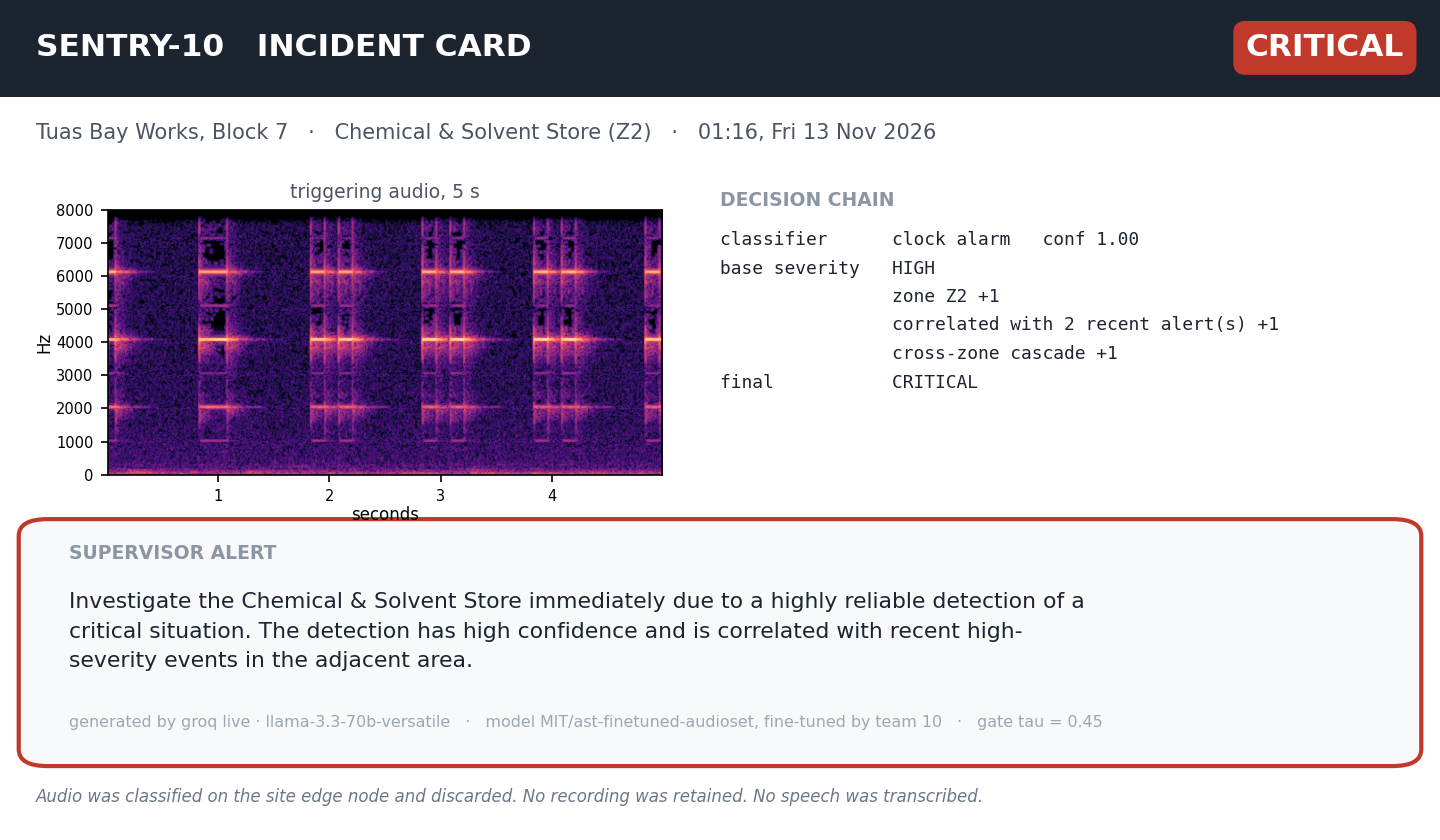

In [ ]:

from matplotlib.patches import Rectangle, FancyBboxPatch

def incident_card(log, out=None):
    out = out or f"{WORKDIR}/incident_card.png"
    crit = [l for l in log if l["severity"] in ("HIGH", "CRITICAL")]
    peak = max(crit, key=lambda l: LADDER.index(l["severity"])) if crit else log[-1]
    ev = next(e for e in EVENTS if e["clock"] == peak["clock"])
    col = SEVCOL[peak["severity"]]

    fig = plt.figure(figsize=(9.6, 5.6)); fig.patch.set_facecolor("white")
    ax = fig.add_axes([0, 0, 1, 1]); ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)

    ax.add_patch(Rectangle((0, 0.885), 1, 0.115, fc="#1c2430"))
    ax.text(0.025, 0.943, "SENTRY-10   INCIDENT CARD", color="white",
            fontsize=15, fontweight="bold", va="center")
    ax.text(0.975, 0.943, peak["severity"], color="white", fontsize=15, fontweight="bold",
            va="center", ha="right",
            bbox=dict(boxstyle="round,pad=0.4", fc=col, ec="none"))

    ax.text(0.025, 0.835, f"Tuas Bay Works, Block 7   ·   {ZONES[peak['zone']]['name']} "
                          f"({peak['zone']})   ·   {peak['clock']}, Fri 13 Nov 2026",
            fontsize=10, color="#4a5563")

    wav_path = f"{AUDIO}/{ev['file']}"
    y = (librosa.load(wav_path, sr=16000, mono=True)[0] if librosa
         else librosa_stub(wav_path))
    if np.any(y):
        sax = fig.add_axes([0.075, 0.435, 0.385, 0.315])
        sax.specgram(y, Fs=16000, NFFT=512, noverlap=384, cmap="magma", vmin=-110, vmax=-20)
        sax.set_title("triggering audio, 5 s", fontsize=9, color="#4a5563")
        sax.tick_params(labelsize=7)
        sax.set_xlabel("seconds", fontsize=8, labelpad=1)
        sax.set_ylabel("Hz", fontsize=8, labelpad=1)

    ax.text(0.50, 0.755, "DECISION CHAIN", fontsize=9, fontweight="bold", color="#8b95a3")
    chain = [f"classifier      {peak['pred'].replace('_',' ')}   conf {peak['conf']:.2f}",
             f"base severity   {BASE_SEV.get(peak['pred'],'INFO')}"]
    chain += [f"                {w}" for w in peak["reasons"]]
    chain += [f"final           {peak['severity']}"]
    ax.text(0.50, 0.725, "\n".join(chain), fontsize=8.6, family="monospace",
            va="top", linespacing=1.75, color="#1c2430")

    ax.add_patch(FancyBboxPatch((0.025, 0.10), 0.95, 0.27,
                                boxstyle="round,pad=0.012,rounding_size=0.02",
                                fc="#f7f9fb", ec=col, lw=2))
    ax.text(0.048, 0.335, "SUPERVISOR ALERT", fontsize=9, fontweight="bold", color="#8b95a3")
    ax.text(0.048, 0.295, textwrap.fill(peak["alert"], 96), fontsize=10.5, va="top",
            linespacing=1.6, color="#1c2430")
    ax.text(0.048, 0.135, f"generated by {peak['alert_source']}   ·   "
                          f"model MIT/ast-finetuned-audioset, fine-tuned by Team 10   ·   "
                          f"gate tau = {TAU}", fontsize=7.6, color="#9aa7b5")

    ax.text(0.025, 0.045, "Audio was classified on the site edge node and discarded. "
                          "No recording was retained. No speech was transcribed.",
            fontsize=8, style="italic", color="#6b7787")
    fig.savefig(out, dpi=150, facecolor="white"); plt.close(fig)
    return out

if DEMO_LOG:
    card = incident_card(DEMO_LOG)
    from IPython.display import Image
    display(Image(card))
else:
    # On "Run all" this cell runs before the app launches, so the log is still empty.
    print("No beats have been run yet. Launch the app (last cell), press NEXT through the")
    print("night, then stop the last cell and re-run this one for the incident card.")


---
## 6 · Audience challenge  ·  *break our model*

Sixty to ninety seconds, and the part people remember. Invite the room to make a noise and let the
monitor react in real time.

**Good prompts, in ascending order of danger to us:**

| Ask for | What should happen | What to say |
|---|---|---|
| A phone alarm | `clock_alarm`, high confidence | "That is the class we actually trained for." |
| One loud clap | `background_other` | "The negative class earning its keep." |
| Jangled keys | honestly, could go either way | "Keys are the classic near-miss for breaking glass." |
| Everyone talking at once | probably `background_other`, low confidence | "It never learned speech, and it correctly refuses to guess." |

**Show a wrong answer on purpose.** A safety system that never admits a false positive is a safety
system nobody trusts. If the model gets something wrong, say so, point at the confidence number, and
explain what the gate `τ` would have done. That is a stronger moment than a clean sweep.

In [ ]:

# Colab microphone recorder. Grant permission the FIRST time you run this, in rehearsal,
# not while the class watches.
from google.colab import output as colab_output
from base64 import b64decode

RECORD_JS = """
const sleep = ms => new Promise(r => setTimeout(r, ms));
var record = time => new Promise(async resolve => {
  const stream = await navigator.mediaDevices.getUserMedia({audio:true});
  const rec = new MediaRecorder(stream);
  const chunks = [];
  rec.ondataavailable = e => chunks.push(e.data);
  rec.start();
  await sleep(time);
  rec.onstop = async () => {
    const blob = new Blob(chunks);
    const reader = new FileReader();
    reader.onloadend = () => resolve(reader.result);
    reader.readAsDataURL(blob);
  };
  rec.stop();
  stream.getTracks().forEach(t => t.stop());
});
"""

def record(seconds=5):
    import librosa
    colab_output.eval_js(RECORD_JS)
    print(f"recording {seconds} s — make your noise NOW")
    b64 = colab_output.eval_js(f"record({seconds*1000})")
    raw = b64decode(b64.split(",")[1])
    with open(f"{WORKDIR}/_challenge.webm", "wb") as f:
        f.write(raw)
    y, _ = librosa.load(f"{WORKDIR}/_challenge.webm", sr=16000, mono=True)
    return y

def challenge(y=None, zone="Z1", clock="02:40", seconds=5):
    if y is None:
        y = record(seconds)
    pred, conf, probs = classify(y)
    sev, why = severity(pred, zone, clock, [])
    alert, src = write_alert(pred, zone, clock, conf, sev, why, [])
    gated = conf < TAU
    display(dashboard(clock=clock, active=zone,
                      state={**{z: ("IDLE", "") for z in ZONE_ORDER}, zone: (sev, pred)},
                      feed=[{"clock": clock, "zone": zone, "label": pred, "severity": sev}],
                      spec=spec_b64(y), probs=probs, status="MONITORING",
                      alert=("<b>Below the confidence gate — the system would have stayed silent.</b><br>"
                             if gated else "") + alert,
                      cue="ask the room whether they agree with it"))
    print(f"\n  top-3: " + "  ".join(
        f"{CLASSES[i]} {probs[i]:.2f}" for i in np.argsort(probs)[::-1][:3]))
    print(f"  gate tau={TAU} -> {'SUPPRESSED' if gated else 'REPORTED'}")
    display(Audio(y, rate=16000))
    return pred, conf

def replay_clip(name=None, zone="Z1", clock="02:40"):
    # REPLAY-mode stand-in for the challenge round: pushes one of the cached demo clips
    # back through the dashboard using its stored prediction. No model, no network.
    ev = (next(e for e in EVENTS if name in e["file"]) if name else EVENTS[4])
    probs = np.zeros(len(CLASSES))
    for lbl, p in ev["top3"]:
        if lbl in CLASSES:
            probs[CLASSES.index(lbl)] = p
    sev, why = severity(ev["pred"], zone, clock, [])
    wav = os.path.join(AUDIO, ev["file"])
    display(dashboard(clock=clock, active=zone,
                      state={**{z: ("IDLE", "") for z in ZONE_ORDER}, zone: (sev, ev["pred"])},
                      feed=[{"clock": clock, "zone": zone, "label": ev["pred"], "severity": sev}],
                      spec=spec_b64(librosa_stub(wav)), probs=probs, status="MONITORING",
                      alert=ev.get("alert", ""), cue="cached replay - no model running"))
    display(Audio(wav, autoplay=True))
    return ev["pred"], ev["conf"]

print("Run  challenge()  to record 5 s from the mic.")
print("Run  challenge(y=some_array)  to classify audio you already have.")
print("If the mic is blocked, use the upload cell below instead.")
if MODE == "REPLAY":
    print("\nMODE is REPLAY: the model is not loaded, so challenge() will refuse.")
    print("Use  replay_clip('glass')  to push a cached clip through the dashboard instead.")

Run  challenge()  to record 5 s from the mic.
Run  challenge(y=some_array)  to classify audio you already have.
If the mic is blocked, use the upload cell below instead.


In [ ]:

# Fallback if the microphone is blocked by the room's machine or browser policy.
def challenge_from_upload():
    assert MODE != "REPLAY", "no model loaded in REPLAY mode - use replay_clip() instead"
    import librosa
    from google.colab import files
    up = files.upload()
    name = list(up)[0]
    y, _ = librosa.load(name, sr=16000, mono=True)
    return challenge(y=y)

# And a zero-risk version: reuse the deliberately hard negatives from the course library.
HARD = ["Gunshot.mp3", "Fireworks_Firecrackers.mp3", "Bottle_Champaigne.mp3", "StaplerGun.mp3"]
def challenge_hard_negative(name="Gunshot.mp3", zone="Z4"):
    if MODE == "REPLAY":
        print("REPLAY mode - falling back to a cached clip.")
        return replay_clip(zone=zone)
    import librosa
    p = os.path.join(SAMPLES, name)
    if not os.path.isfile(p):
        print(f"{name} not found in {SAMPLES} - falling back to a cached demo clip.")
        return replay_clip(zone=zone)
    y, _ = librosa.load(p, sr=16000, mono=True, duration=5.0)
    print(f"{name} — a broadband transient that is NOT breaking glass. Watch what it does.")
    return challenge(y=y, zone=zone, clock="02:44")
print("backup options ready:  challenge_from_upload()  |  challenge_hard_negative('Gunshot.mp3')")

backup options ready:  challenge_from_upload()  |  challenge_hard_negative('Gunshot.mp3')



---
## 7 · Incident report

Closes the loop: the night's log, the model's accuracy on the eight demo events, and the honest
numbers behind it. Leave this on screen for questions.

In [ ]:

import pandas as pd

if not DEMO_LOG:
    # On "Run all" this cell runs BEFORE the app launches, so nothing has happened yet.
    print("No beats have been run yet. Launch the app (last cell), press NEXT through the")
    print("night, then stop the last cell and re-run this one for the incident report.")
else:
    df = pd.DataFrame(DEMO_LOG)
    n_ok = int(df.correct.sum())

    # Build every derived sentence BEFORE the HTML. Arithmetic and conditionals inside a
    # large f-string are how you get an unreadable traceback in front of an audience.
    probe_pct   = f"{M('linear_probe_accuracy'):.1%}"
    indom_pct   = f"{METRICS['in_domain_accuracy']:.1%}"
    unseen_pct  = f"{M('unseen_negative_false_alarm_rate'):.1%}"
    n_unseen    = METRICS.get("n_unseen_negatives", 0)
    chan_pct    = f"{M('channel_shift_recall'):.1%}"
    # Say plainly which way the fine-tune vs linear-probe comparison went.
    if M('linear_probe_accuracy') >= METRICS['in_domain_accuracy']:
        probe_sentence = ("on this small test fold the linear probe matched or beat the "
                          "fine-tune, so the frozen AudioSet features already do most of the work.")
    else:
        probe_sentence = "that difference is what the fine-tune bought."
    if METRICS.get("have_cross_source"):
        xs_sentence = (f"Recall on cross-source positives from a genuinely different recording "
                       f"chain: <b>{M('cross_source_recall_exact'):.1%}</b> "
                       f"(n={METRICS.get('n_cross_source_pos_exact', '?')}).")
    else:
        xs_sentence = ("The optional cross-source evaluation on the course sample library was not "
                       "run for this build.")

    display(HTML(f"""
    <div style="font-family:system-ui;max-width:980px">
    <h3 style="margin:0 0 4px">Night-shift incident report &nbsp;·&nbsp; Fri 13 Nov 2026</h3>
    <div style="color:#6b7787;font-size:13px;margin-bottom:12px">
    Tuas Bay Works Block 7 &nbsp;·&nbsp; {len(df)} detections &nbsp;·&nbsp;
    {(df.severity.isin(['HIGH','CRITICAL'])).sum()} escalated</div>
    <table style="border-collapse:collapse;font-size:12px;width:100%">
    <tr style="background:#1c2430;color:#fff">
      <th style="padding:6px 8px;text-align:left">time</th>
      <th style="padding:6px 8px;text-align:left">zone</th>
      <th style="padding:6px 8px;text-align:left">detected</th>
      <th style="padding:6px 8px;text-align:right">conf</th>
      <th style="padding:6px 8px;text-align:left">severity</th>
      <th style="padding:6px 8px;text-align:left">why</th></tr>
    {''.join(
      f"<tr style='border-bottom:1px solid #eef1f4;background:{'#fff' if i%2 else '#fafbfc'}'>"
      f"<td style='padding:5px 8px;font-family:ui-monospace'>{r.clock}</td>"
      f"<td style='padding:5px 8px'>{r.zone}</td>"
      f"<td style='padding:5px 8px'>{r.pred.replace('_',' ')}"
      f"{'' if r.correct else ' <span style=color:#c0392b>(mis-classified)</span>'}</td>"
      f"<td style='padding:5px 8px;text-align:right;font-family:ui-monospace'>{r.conf:.2f}</td>"
      f"<td style='padding:5px 8px;color:{SEVCOL[r.severity]};font-weight:700'>{r.severity}</td>"
      f"<td style='padding:5px 8px;color:#6b7787;font-size:11px'>{'; '.join(r.reasons) or '—'}</td></tr>"
      for i, r in enumerate(df.itertuples()))}
    </table>
    <div style="margin-top:14px;padding:11px 14px;background:#f7f9fb;border-left:4px solid #2c5f8a;
                font-size:13px;line-height:1.65">
    <b>The honest numbers.</b>
    Model accuracy on tonight's events: <b>{n_ok}/{len(df)}</b>.
    Held-out ESC-50 fold 5: <b>{indom_pct}</b> for the fine-tuned model, versus <b>{probe_pct}</b>
    for a linear probe on the frozen backbone — {probe_sentence}
    False alarms on <b>{n_unseen}</b> impulsive clips the model has never seen in any form
    (fireworks, can opening, door knock, mouse click, clapping, typing): <b>{unseen_pct}</b>.
    Recall through a deliberately degraded recording channel: <b>{chan_pct}</b>.
    {xs_sentence}
    Trained on {METRICS['n_train']} ESC-50 clips ({METRICS.get('epochs', '?')} epochs) on one T4.
    </div></div>"""))

    df.to_csv(f"{WORKDIR}/sentry10_incident_log.csv", index=False)
    print(f"\nlog written to {WORKDIR}/sentry10_incident_log.csv")


time,zone,detected,conf,severity,why
22:04,Z1,engine,1.00,INFO,zone Z1 -1; out of hours +1
22:31,Z3,crying baby,1.00,INFO,zone Z3 -2
23:47,Z4,car horn,1.00,INFO,zone Z4 -1
01:12,Z1,chainsaw,1.00,HIGH,out of hours +1
01:14,Z1,glass breaking,1.00,HIGH,zone Z1 -1; out of hours +1; correlated with 1 recent alert(s) +1
01:16,Z2,clock alarm,1.00,CRITICAL,zone Z2 +1; correlated with 2 recent alert(s) +1; cross-zone cascade +1
01:17,Z3,crying baby,1.00,HIGH,zone Z3 -2 SUPPRESSION REVOKED (incident open); correlated with 3 recent alert(s) +1
01:22,Z4,siren,1.00,MEDIUM,"response class, exempt from escalation"



log written to /content/sentry10_incident_log.csv



---
## 8 · What we would fix

Say these out loud before anyone asks. Volunteering a limitation reads as competence; being caught by
one does not.

* **One label per five-second window.** Real incidents overlap — an alarm sounding *while* someone
  shouts. Multi-label with per-class thresholds is the obvious next version.
* **`clock_alarm` is standing in for a fire-alarm sounder.** Related, not identical. We say so in the
  report rather than quietly hoping nobody notices.
* **Forty clips per class.** ESC-50 is small. Our confidence intervals are wide and we have not
  pretended otherwise.
* **The zone-severity matrix is hand-written by us, not learned.** That is a deliberate choice — a
  safety escalation policy should be auditable by the safety officer, not inferred from data. But it
  does mean the "intelligence" in the escalation is ours, and the LLM's job is presentation and
  correlation, not policy.
* **We never tested on a real factory floor.** Everything here is ESC-50 plus a course sample library.
  The 78–84 dBA machine-hall baseline in our case study is a claim about the world, not a measurement
  we made.

---

### If something goes wrong mid-demo

1. Audio silent → re-run the **audio primer** cell, click play, carry on.
2. Groq hangs → it degrades to cached text by itself; keep talking, do not touch it.
3. GPU lost or model errors → set `MODE_OVERRIDE = "REPLAY"` in the config cell and Run all again (cached predictions, no model).

---
## 9 · Launch the demo

The app was built in section 5; this cell starts it with a public share link. Open the link **in a new
tab**, press **🔊 test the PA**, then **▶ NEXT** through the night (or make the sound the NEXT button is
pointing at into the microphone). When you are done, stop this cell and re-run the incident card and
incident report cells to see the night's log.


In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
#  LAUNCH THE DEMO (last cell).  Open the public URL printed below IN A NEW TAB.
#  debug=True keeps this cell running so the share link stays up. When the demo is
#  over, stop this cell (■) and re-run the incident card / incident report cells above.
# ══════════════════════════════════════════════════════════════════════════════
print("MODE =", MODE, "| tau =", TAU, "| beats:", " -> ".join(e["beat"] for e in EVENTS))
try:
    demo_app.launch(share=True, debug=True, show_error=True, inline=True,
                    allowed_paths=_ALLOW, **_LAUNCH_KW)
except TypeError:
    # very old gradio without allowed_paths
    demo_app.launch(share=True, debug=True, show_error=True, inline=True,
                    **_LAUNCH_KW)
